<div><center><img src="https://ml.ucv.ai/logo.png\" width=150"/> </center></div>

# 05| Componentes de Redes Neuronales Profundas

1. Procesamiento digital de imágenes
1. Redes Convolucionales (CNN)

## Versión v.2 (15/09/2026)

- **Sección 1.4**: nota sobre convolución vs. correlación cruzada (lo que realmente calculan Keras/PyTorch) con verificación en código.
- **Sección 2.1**: corregido el conteo de parámetros (3072 pesos *por neurona*); reescrito el argumento de la permutación de píxeles; comparación numérica lineal vs. conv en función de la resolución; nota sobre equivarianza/invarianza.
- **Sección 2.2**: fórmula del tamaño de salida (padding, stride, dilatación) con verificación; campo receptivo; respuesta explícita a "¿qué cambia respecto a una capa lineal?" con tabla y demo de la convolución como matriz de Toeplitz; verificación del conteo de parámetros contra `model.summary()`; Flatten vs. Global Average Pooling; corrección de la sección de upsampling; sección de normalización reescrita (BatchNorm primero, LayerNorm/GroupNorm como alternativas); texto de Dropout.
- **Ejemplo Sign MNIST (Keras)**: reestructurado como comparación FNN vs. CNN con `build_*()` y `run_experiment()` que devuelve resultados. Corregidos: entradas sin escalar (la red no aprendía, ~4% = azar), `Normalization()` sin `adapt()`, CNN que colapsaba a 1×1 espacial, variable `history` indefinida. Añadidos: gráfica comparativa, tabla resumen y experimento opcional de píxeles permutados.
- **Ejemplo Sign MNIST (PyTorch)**: etiquetas remapeadas a 0..23 (la falta de remapeo causaba el `device-side assert`), `n_classes` consistente, selección de dispositivo simplificada, `return xz` → `return x`.
- Correcciones menores: `ver_img`, numeración 1.3.d, kernel de realce mal etiquetado, cita de AlexNet (*overfitting*), enlaces de imagen rotos.

## Versión v.1

El notebook lo puedo modificar, esta versión es la v.1 a 01/06/2025 a las 2pm de Caracas.

- Agregado ejemplo de FNN con MNIST. Fácilmente modificable con CNN.

Basado en:
- Operaciones: https://docs.opencv.org/3.4/d5/d98/tutorial_mat_operations.html
- Blending: https://docs.opencv.org/3.4/d5/dc4/tutorial_adding_images.html
- https://cs231n.github.io/convolutional-networks/
- “Understanding Convolution in Deep Learning” Dettmers, Tim. TD Blog, 26 Mar 2015.
- “Convolutional Neural Networks for Visual Recognition” Li, Fei-Fei et al. Stanford University Courses, Spring 2017.
- https://developer.nvidia.com/discover/convolutional-neural-network

## Aprendizaje Automático [UCV]

* Autor: Fernando Crema García
* Contacto: fernando.cremagarcia@kuleuven.be; fernando.cremagarcia@esat.kuleuven.be

---

# 1. Procesamiento de imágenes



## 1.1 Imágenes

### Escala de grises

Una imagen en escala de grises de altura $M$ y anchura $N$ es representada como una matriz bidimensional  $$
I(x, y) \in \mathbb{R}^{M \times N}
$$
donde $I(x, y)$ representa la intensidad del pizel en la posición x, y

### Imágenes a color

Una imagen a color $I_c$, la representamos como un conjunto de tres matrices bidimensionales correspondientes a los canales de color rojo, verde y azul (RGB) representados por $c \in \{R, G, B\}$ $$
I_c(x, y, c) \in \mathbb{R}^{M \times N \times 3}
$$

### Imágenes a color con canal alpha

- Una imagen a color con canal alpha $I_{ca}$ la representamos como un conjunto de cuatro matrices bidimensionales correspondientes a los canales de color rojo, verde y azul (RGB) para el color y una matriz extra del canal alpha.

La matriz extra $A(x, y) \in[0,1]($ or $[0,255])$ nos sugiere qué tanto del color en el pixel $(x, y)$ es mantenido.

## 1.2 Operadores

Un operador en una imagen es una función que toma como entrada 1 o más imagénes y produce como resultado una imagen.

Un operador puede ser:
- Operadores de puntos (transformaciones de píxeles)
- Operadores de vecindades (basado en área)

## 1.3 Operadores de punto

- La función de entrada debe depender solamente del píxel actual y de parámetros globales para toda la función.
- Ejemplos de estos operadores:
  1. Brillo
  1. Contraste
  1. Corrección de color
  1. Transformaciones



In [ ]:
def comparar_img(img1, img2, t1, t2):
  # Display the original and adjusted images
  fig, ax = plt.subplots(1, 2, figsize=(10, 5))
  ax[0].imshow(img1, cmap='gray')
  ax[0].set_title(t1)
  ax[0].axis('off')


  ax[1].imshow(img2, cmap='gray')
  ax[1].set_title(t2)
  ax[1].axis('off')

  plt.show()

In [ ]:
def ver_img(img1, t1):
  fig, ax = plt.subplots(1, 1, figsize=(10, 5))
  ax.imshow(img1, cmap='gray')
  ax.set_title(t1)
  ax.axis('off')

  plt.show()

### 1.3.a Brillo y contraste

Una definición básica de una función puede ser como: $$S(i, j)=\alpha \cdot P(i, j)+\beta$$

Dónde:
1. $P$ es el píxel $(i, j)$ de la imagen.
1. $S$ es el píxel $(i, j)$ de la imagen de salida.
1. $\alpha$ podría ser considerado como ganancia.
1. $\beta$ podría ser considerado como sesgo

En general, la ganancia incrementa el contraste y el sesgo el brillo.

#### Ejemplo 1: OpenCV

In [ ]:
import cv2 as cv
import numpy as np
from google.colab.patches import cv2_imshow

In [ ]:
image = cv.imread("family.jpg")

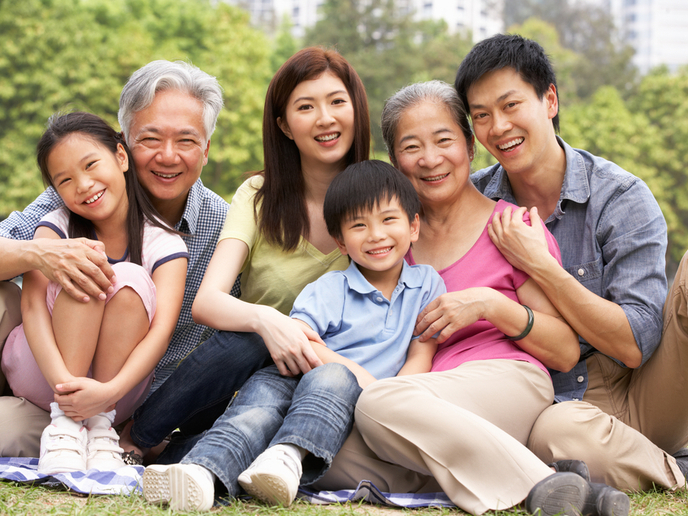

In [ ]:
cv2_imshow(image)

In [ ]:
alpha = 1.8 # Valores usuales de 1 a 3
beta = 0

In [ ]:
image.shape

(516, 688, 3)

In [ ]:
height, length, channels = image.shape

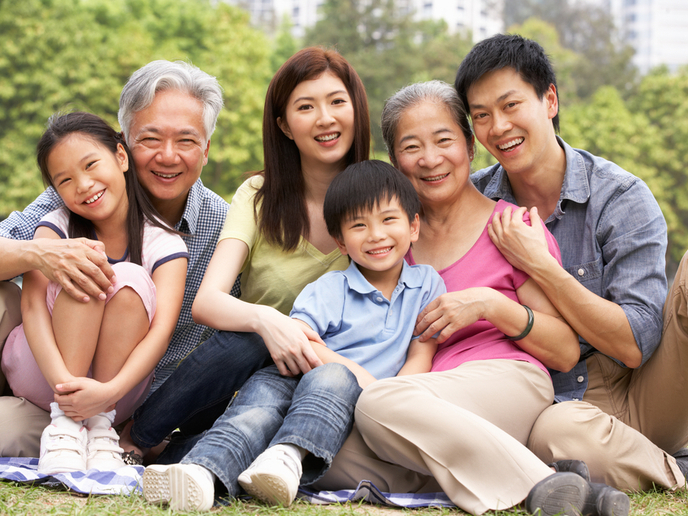

In [ ]:
cv2_imshow(image)

In [ ]:
S = np.zeros(image.shape, image.dtype)
for h in range(height):
  for l in range(length):
    for c in range(channels):
      S[h, l, c] = np.clip(alpha * image[h, l,c] + beta, 0, 255)

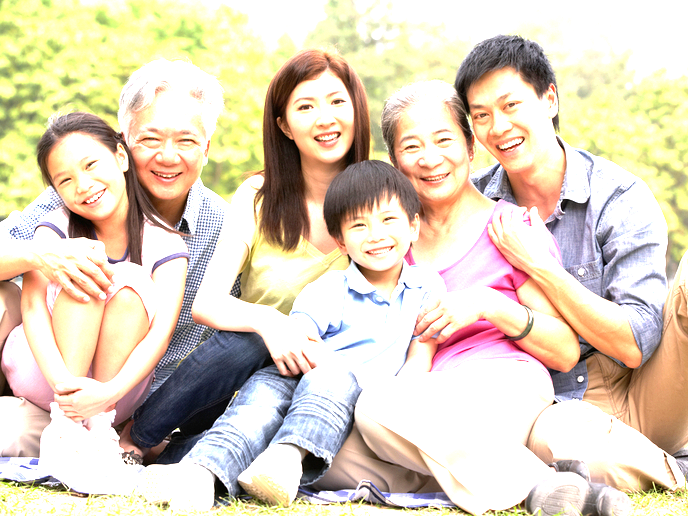

In [ ]:
cv2_imshow(S)

In [ ]:
S_cv = cv.convertScaleAbs(image, alpha=alpha, beta=beta)

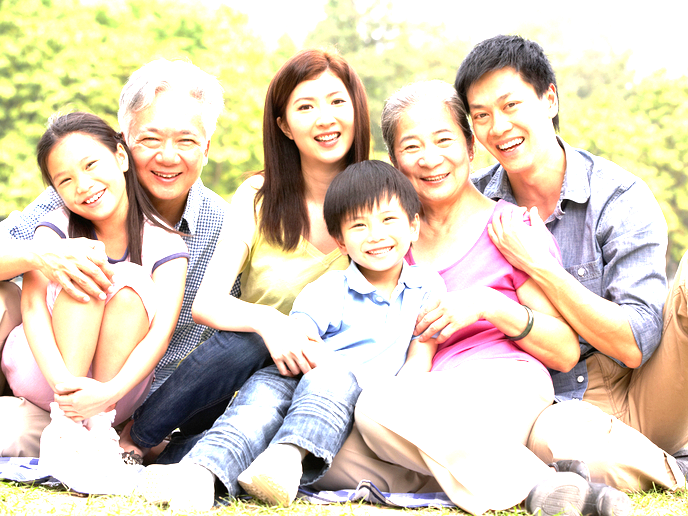

In [ ]:
cv2_imshow(S_cv)

#### Cómo podemos verificar que son iguales

array([[[0, 0, 1],
        [0, 0, 0],
        [0, 1, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[1, 1, 0],
        [1, 0, 1],
        [0, 1, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       [[0, 0, 0],
        [1, 0, 0],
        [1, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [0, 0, 0]],

       ...,

       [[0, 0, 0],
        [1, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [1, 0, 0]],

       [[1, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [1, 0, 0],
        [1, 0, 0]],

       [[0, 0, 0],
        [0, 0, 0],
        [0, 0, 0],
        ...,
        [0, 0, 0],
        [0, 0, 0],
        [1, 0, 0]]], dtype=uint8)
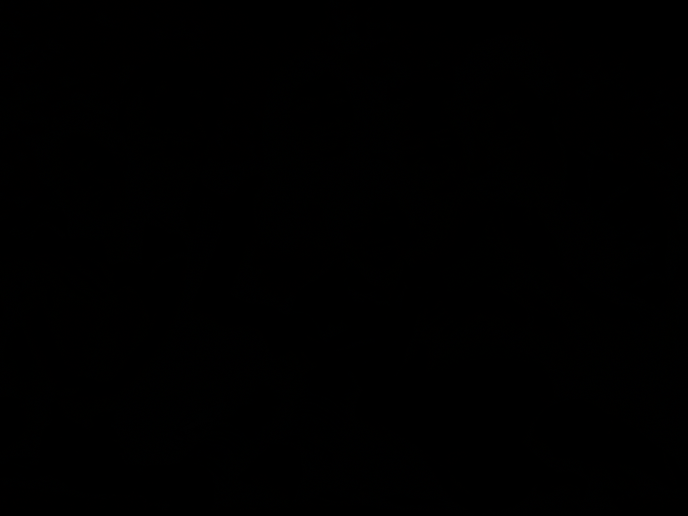

In [ ]:
S_cv - S

array([[[ 59, 100,  91],
        [ 59, 109,  99],
        [ 63, 116, 104],
        ...,
        [246, 244, 244],
        [247, 245, 245],
        [246, 244, 243]],

       [[ 61, 100,  93],
        [ 61, 114, 106],
        [ 70, 126, 118],
        ...,
        [248, 244, 243],
        [246, 244, 244],
        [247, 245, 245]],

       [[ 59, 105,  93],
        [ 65, 119, 109],
        [ 75, 133, 124],
        ...,
        [247, 242, 243],
        [245, 243, 243],
        [248, 244, 243]],

       ...,

       [[104, 165, 167],
        [120, 173, 189],
        [144, 181, 207],
        ...,
        [130, 193, 183],
        [ 89, 169, 156],
        [ 85, 168, 156]],

       [[136, 189, 195],
        [155, 192, 206],
        [165, 194, 215],
        ...,
        [154, 205, 197],
        [116, 185, 178],
        [105, 181, 173]],

       [[134, 189, 196],
        [166, 201, 215],
        [178, 204, 220],
        ...,
        [109, 173, 177],
        [ 89, 162, 166],
        [ 96, 170, 168]]], dtype=uint8)
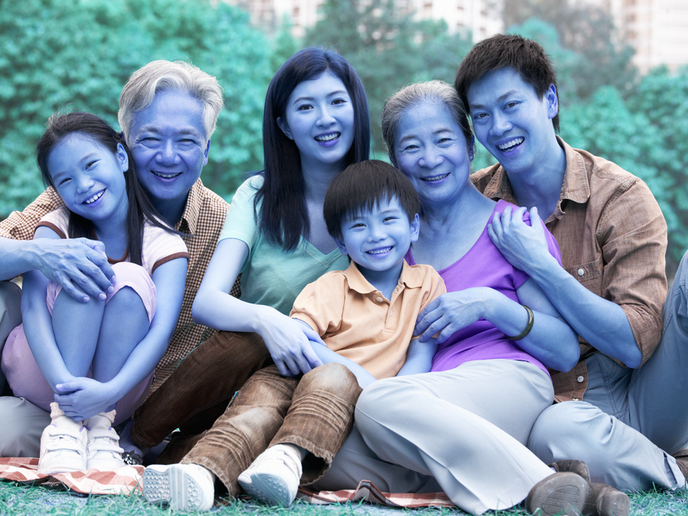

In [ ]:
image - (S_cv - S)

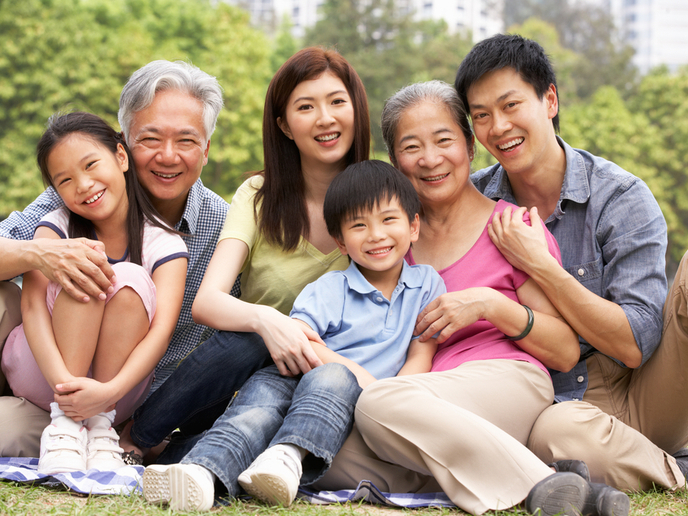

In [ ]:
cv2_imshow(img)

#### Ejemplo 3: Una imagen "mala"

Imagen de Visem  [CC BY-SA 3.0], via Wikimedia Commons

In [ ]:
bad_image = cv.imread("darkphoto.png")

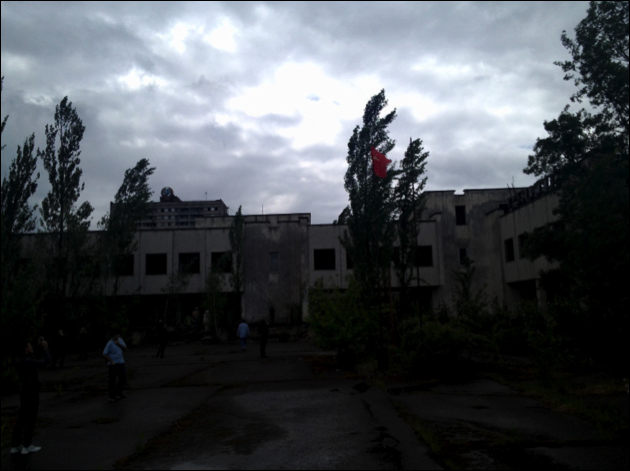

In [ ]:
cv2_imshow(bad_image)

#### Viendo el histograma de la imagen

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import io

def plot_histogram(image):
  # Calcular el histograma para cada canal de color
  colors = ('r', 'g', 'b')
  for i, color in enumerate(colors):
      histogram, bin_edges = np.histogram(
          image[:, :, i], bins=256, range=(0, 256))

      # Trazar el histograma
      plt.plot(bin_edges[0:-1], histogram, color=color)

  plt.title("Histograma de la Imagen a Color")
  plt.xlabel("Valor del Píxel")
  plt.ylabel("Frecuencia")
  plt.xlim([0, 256])
  plt.show()

def plot_histogram_gris(image_gray):
  # Calcular el histograma
  histogram, bin_edges = np.histogram(image_gray, bins=256, range=(0, 1))

  # Trazar el histograma
  plt.figure()
  plt.title("Histograma de la Imagen en Escala de Grises")
  plt.xlabel("Valor del Píxel")
  plt.ylabel("Frecuencia")
  plt.xlim([0.0, 1.0])  # <- considerando que la imagen está normalizada entre 0 y 1
  plt.plot(bin_edges[0:-1], histogram)  # <- trazar histograma
  plt.show()

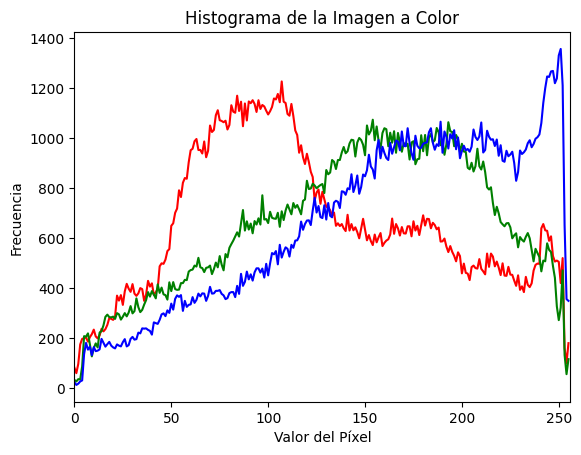

In [ ]:
plot_histogram(image=bad_image.copy())

Lo natural es intentar modificar el histograma porque la mayoría de píxeles están a la derecha

In [ ]:
alpha = 1.3
beta = 40

In [ ]:
S_mala = cv.convertScaleAbs(bad_image, alpha=alpha, beta=beta)

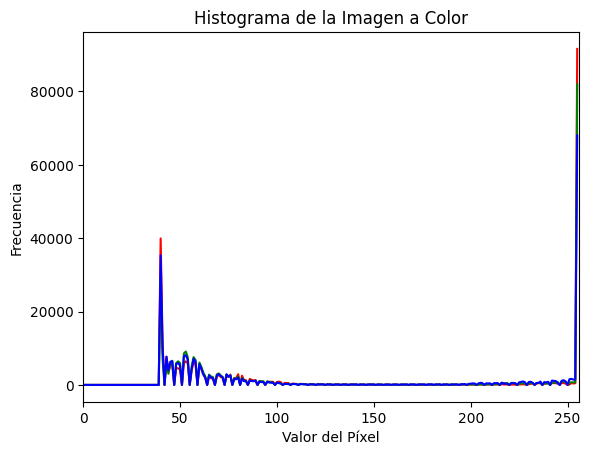

In [ ]:
plot_histogram(S_mala)

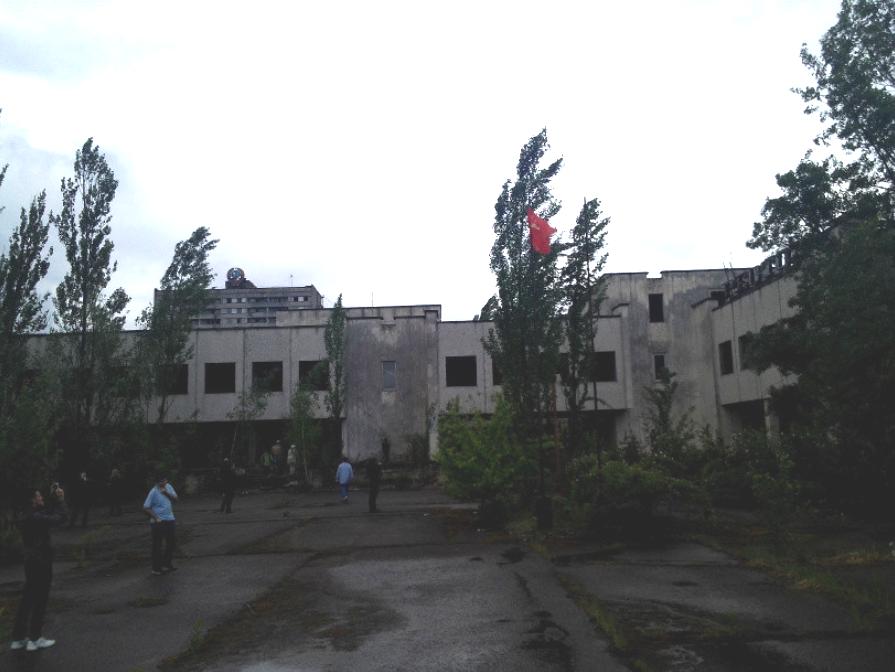

In [ ]:
cv2_imshow(S_mala)

#### Ejemplo 2: skimage

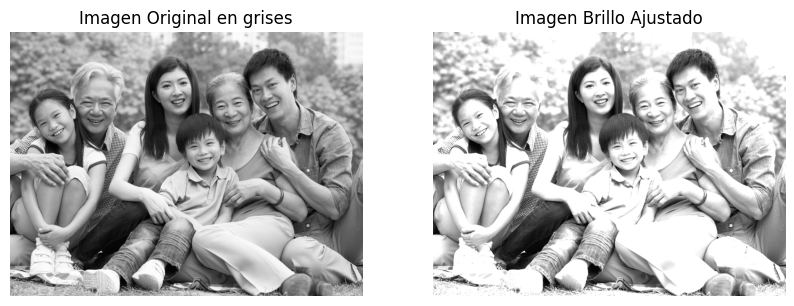

In [ ]:
import numpy as np
from skimage import io
from skimage import exposure
from skimage import color
import matplotlib.pyplot as plt

# Cargar la imagen
image = io.imread('family.jpg')

# Convertir a escala de grises
image_gray = color.rgb2gray(image)

# Ajustar brillo y contraste con skimage
ganancia = 1
sesgo = 0.3
brightness_adjusted = np.clip(ganancia*image_gray + sesgo, 0, 1)

# Ver imágenes
comparar_img(image_gray, brightness_adjusted, "Imagen Original en grises", "Imagen Brillo Ajustado")


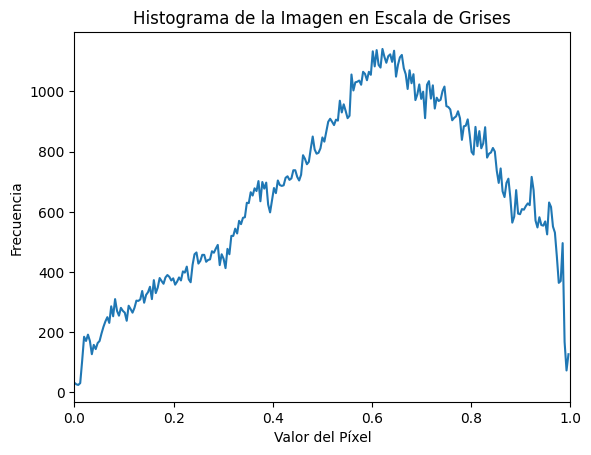

In [ ]:
plot_histogram_gris(image_gray=image_gray.copy())

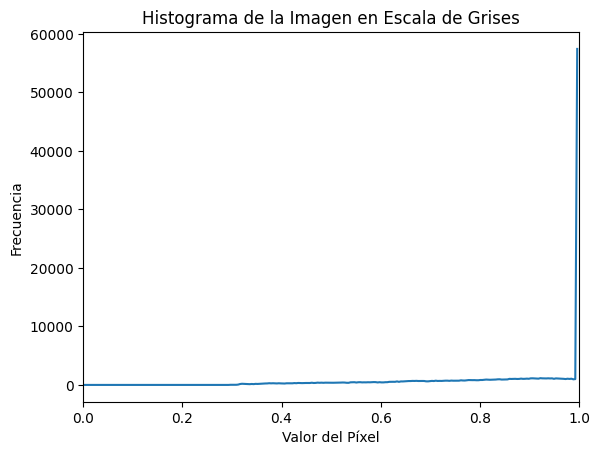

In [ ]:
plot_histogram_gris(image_gray=brightness_adjusted.copy())

### 1.3.b Corrección gamma

Otro método para corregir brillo usando una transformación no lineal de los píxeles dependiendo de un valor global gamma ($\gamma$)

En este caso tenemos: $$S(i, j)=\left(\frac{P(i, j)}{255}\right)^\gamma \times 255$$

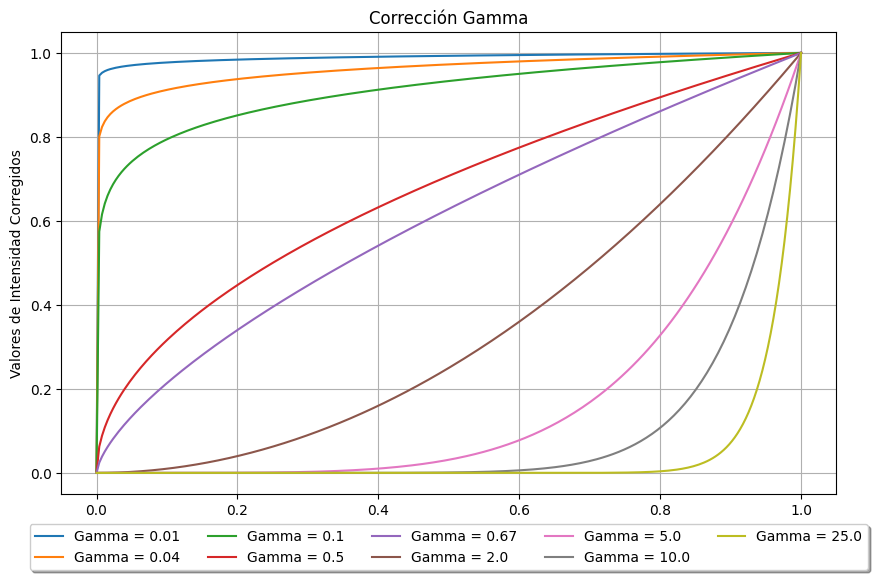

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Crear una matriz de valores de intensidad de píxeles de 0 a 1
intensity_values = np.linspace(0, 1, 256)

# Valores preseleccionados de gamma
gamma_values = [0.01, 0.04, 0.1, 0.5, 0.67, 2.0, 5.0, 10.0, 25.0]

# Graficar la corrección gamma para cada valor preseleccionado
plt.figure(figsize=(10, 6))

for gamma in gamma_values:
    corrected_values = np.power(intensity_values, gamma)
    plt.plot(intensity_values, corrected_values, label=f'Gamma = {gamma}')

plt.title('Corrección Gamma')
plt.xlabel('Valores de Intensidad Originales')
plt.ylabel('Valores de Intensidad Corregidos')
# Put a legend below current axis
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05),
          fancybox=True, shadow=True, ncol=5)
plt.grid(True)
plt.show()


Es fácil entender que:

Cuando $\gamma<1$, los valores oscuros tendrán más brillo y el histograma se desplazará hacia la derecha mientras que ocurrirá el efecto contrario para valores donde $\gamma>1$

In [ ]:
gamma = 0.4
lookUpTable = np.empty((1,256), np.uint8)
for i in range(256):
    lookUpTable[0,i] = np.clip(pow(i / 255.0, gamma) * 255.0, 0, 255)

S_gamma = cv.LUT(bad_image, lookUpTable)


In [ ]:
S_gamma = cv.LUT(bad_image, lookUpTable)

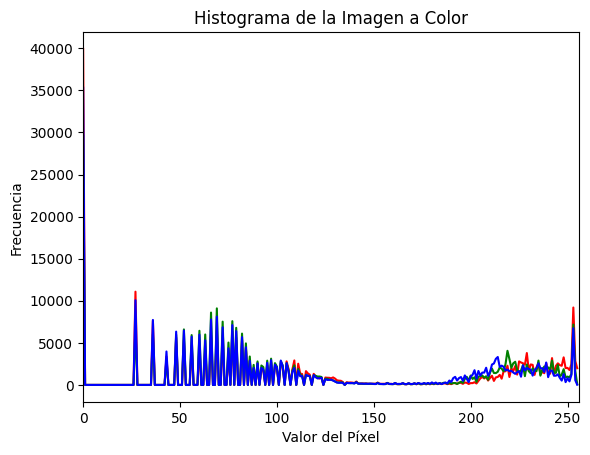

In [ ]:
plot_histogram(image=S_gamma)

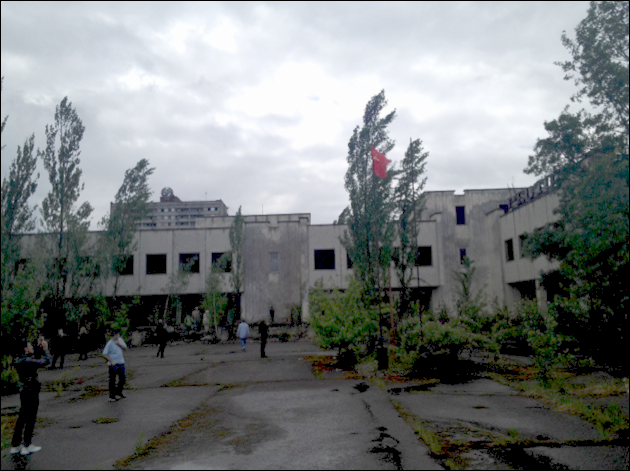

In [ ]:
cv2_imshow(S_gamma)

### 1.3.c  Marca de agua: Image blending

En la definición de operadores de punto establecimos claramente que la entrada pueden ser dos imágenes.

Si quisiéramos agregar una marca de agua a una imagen pudiésemos usar el operador linear de mezcla (linear blending operator)

Es bastante intuitiva la definición: $$
S(i, j)=(1-\alpha) P_0(i, j)+\alpha P_1(i, j)
$$

Es la combinación convexa de dos imagenes ponderadas por un valor alfa ($\alpha$)

In [ ]:
me = cv.imread('totti.jpg', cv.IMREAD_UNCHANGED)
real_madrid = cv.imread('real_madrid_logo.png', cv.IMREAD_UNCHANGED) # , cv2.IMREAD_UNCHANGED

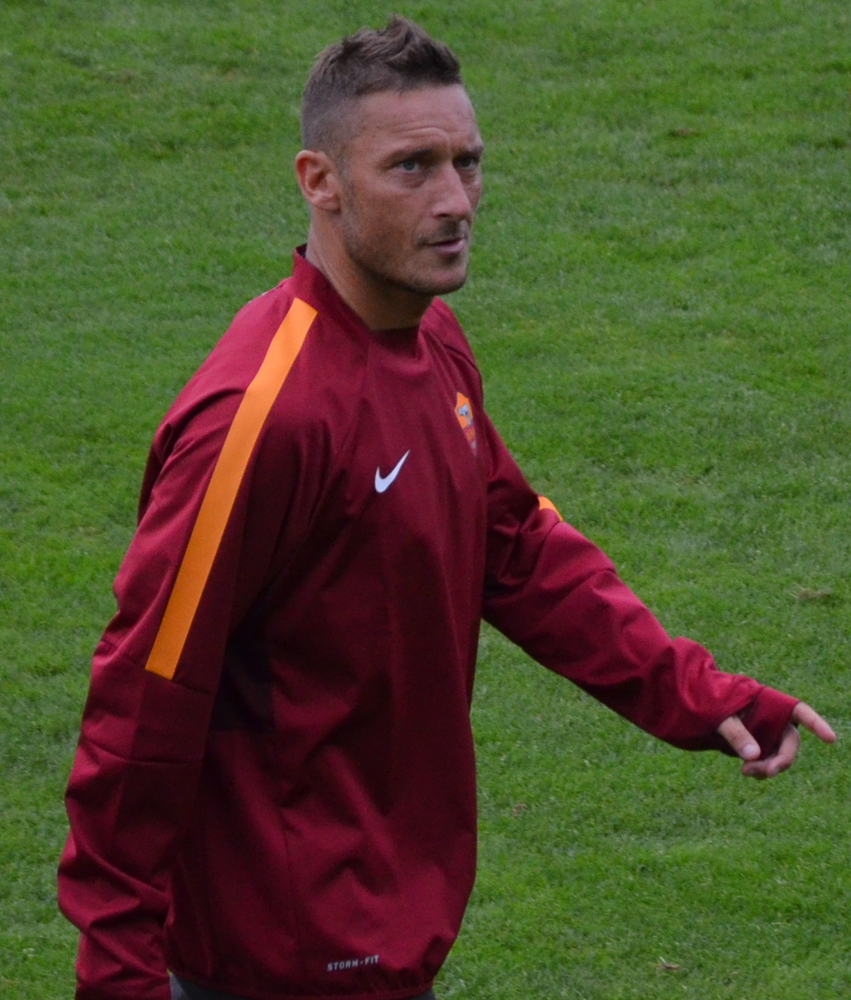

In [ ]:
cv2_imshow(me)

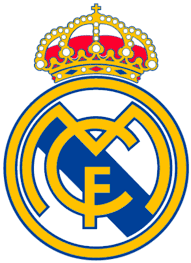

In [ ]:
cv2_imshow(real_madrid)

In [ ]:
me.shape

(1323, 1127, 3)

In [ ]:
real_madrid.shape

(263, 191, 3)

In [ ]:
alpha = 0.7
beta = (1.0 - alpha)
dst = cv.addWeighted(me, alpha, real_madrid, beta, 0.0)

error: OpenCV(4.11.0) /io/opencv/modules/core/src/arithm.cpp:662: error: (-209:Sizes of input arguments do not match) The operation is neither 'array op array' (where arrays have the same size and the same number of channels), nor 'array op scalar', nor 'scalar op array' in function 'arithm_op'


#### Qué va a pasar?

In [ ]:
real_madrid.shape

(263, 191, 3)

In [ ]:
me.shape

(1323, 1127, 3)

In [ ]:
# Especificar las coordenadas de inicio (x, y), el ancho (w) y la altura (h)
size = 191
x, y, w, h = 0, 0, 0+size, 0+size # Ejemplo de valores

# Recortar la imagen
cropped_real_madrid = real_madrid[y:y+h, x:x+w]

In [ ]:
# Especificar las coordenadas de inicio (x, y), el ancho (w) y la altura (h)
size = 191
x, y, w, h = 100, 600, 0+size, 0+size # Ejemplo de valores

# Recortar la imagen
cropped_me = me[y:y+h, x:x+w]

In [ ]:
cropped_real_madrid.shape

(191, 191, 3)

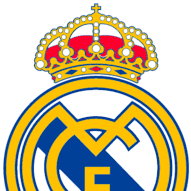

In [ ]:
cv2_imshow(cropped_real_madrid)

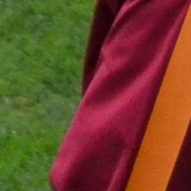

In [ ]:
cv2_imshow(cropped_me)

In [ ]:
alpha = 0.7
beta = (1.0 - alpha)
dst = cv.addWeighted(cropped_me, alpha, f(cropped_real_madrid), beta, 0.0)

In [ ]:
# TODO

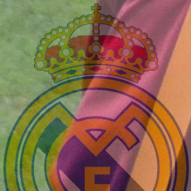

In [ ]:
cv2_imshow(dst)

Ideas:

1. Crop el logo en la zona interesante
1. Reducir o aumentar dimensión
1. Usar padding para colocarlo en la imagen original

### 1.3.d Aplicaciones: Indagando el texto

In [ ]:
misterio = cv.imread('darkbook.png', cv.IMREAD_UNCHANGED)

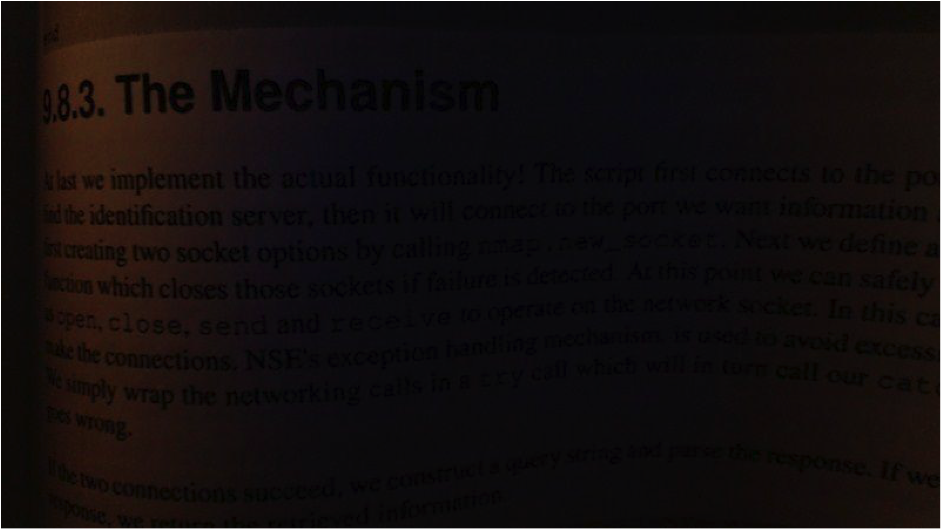

In [ ]:
cv2_imshow(misterio)

In [ ]:
gamma = 0.3
lookUpTable = np.empty((1,256), np.uint8)
for i in range(256):
    lookUpTable[0,i] = np.clip(pow(i / 255.0, gamma) * 255.0, 0, 255)

S_misterio = cv.LUT(misterio, lookUpTable)


In [ ]:
S_misterio.shape

(530, 942, 4)

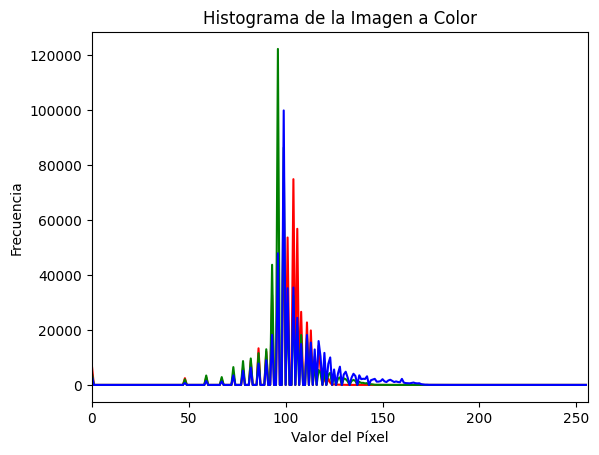

In [ ]:
plot_histogram(image=S_misterio)

In [ ]:
W, H, C = S_misterio.shape

t = 100

S = np.zeros(S_misterio.shape, image.dtype)
for h in range(H):
  for w in range(W):
    for c in range(C):
      S[w, h, c] = 0 if S_misterio[w, h, c] <= t else 255

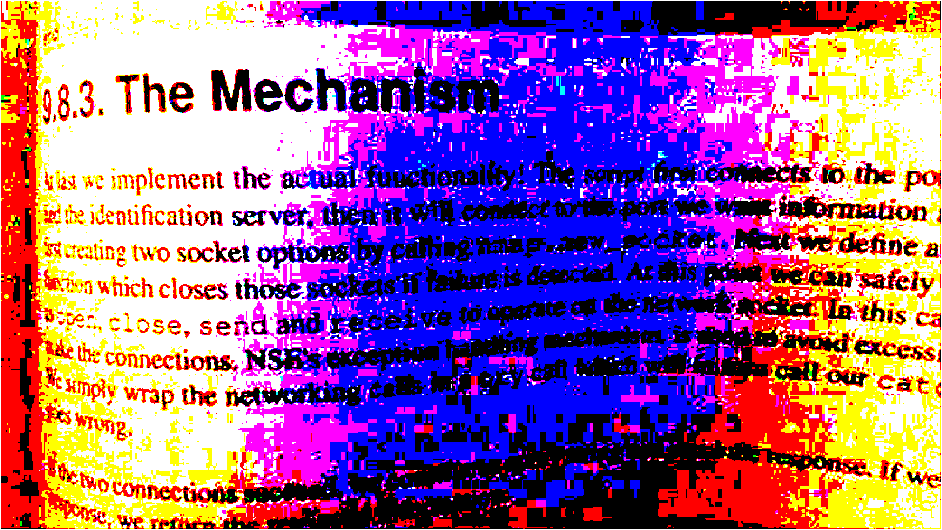

In [ ]:
cv2_imshow(S)

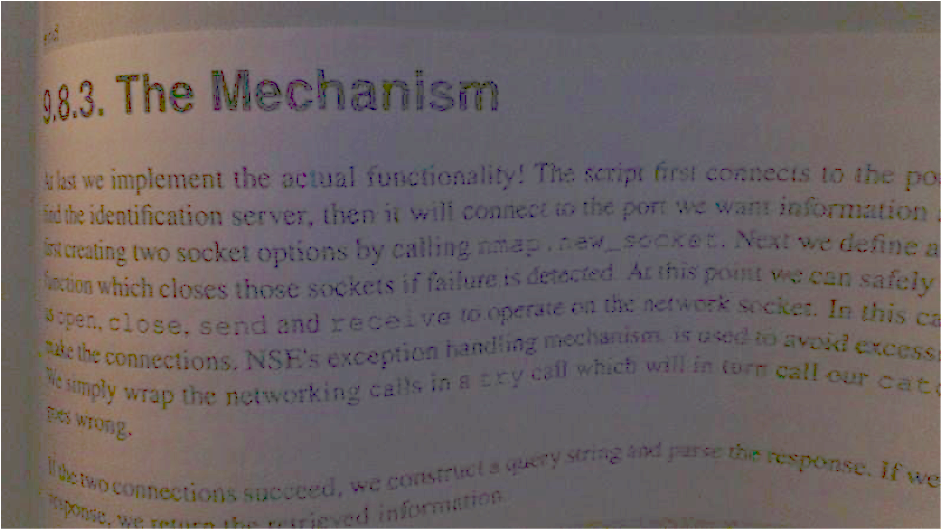

In [ ]:

cv2_imshow(S_misterio)

## 1.4 Operadores de vecindad

### 1.4.a Convolución

Convolución es el proceso de transformar cada elemento de una imagen usando un kernel (filtro) de dimensión reducida tomando en cuenta los vecinos del píxel de interés.

La definición general de la operación de convolución para una submatriz de $X$ de dimensión $m \times n$ contra el kernel $K$ de dimensión $m \times n$ es:

$$
K_{m,n} * X_{m, n} = \left[\begin{array}{cccc}
k_{11} & k_{12} & \cdots & k_{1 n} \\
k_{21} & k_{22} & \cdots & k_{2 n} \\
\vdots & \vdots & \ddots & \vdots \\
k_{m 1} & k_{m 2} & \cdots & k_{m n}
\end{array}\right] * \left[\begin{array}{cccc}
x_{11} & x_{12} & \cdots & x_{1 n} \\
x_{21} & x_{22} & \cdots & x_{2 n} \\
\vdots & \vdots & \ddots & \vdots \\
x_{m 1} & x_{m 2} & \cdots & x_{m n}
\end{array}\right]=\sum_{i=0}^{m-1} \sum_{j=0}^{n-1} k_{(1+i)(1+j)} x_{(m-i)(n-j)}
$$

En general, los kernel serán más pequeños que la imagen original. Supongamos que tenemos el kernel

$$
K = \left[\begin{array}{lll}
a & b & c \\
d & e & f \\
g & h & i
\end{array}\right]
$$

y la imagen 5x5
$$
\left[\begin{array}{lll}
1 & 2 & 3 & 4 & 5\\
6 & 7 & 8 & 9 & 10 \\
11 & 12 & 13 & 14 & 15 \\
16 & 17 & 18 & 19 & 20 \\
21 & 22 & 23 & 24 & 25
\end{array}\right]
$$

Aplicar la convolución en el píxel $(2, 2)$ usando el Kernel $K$ viene reflejado como:

$$
\left(\left[\begin{array}{lll}
a & b & c \\
d & e & f \\
g & h & i
\end{array}\right] *\left[\begin{array}{lll}
1 & 2 & 3 \\
6 & 7 & 8 \\
11 & 12 & 13
\end{array}\right]\right)[2,2]=(i \cdot 1)+(h \cdot 2)+(g \cdot 3)+(f \cdot 6) +(e \cdot 7)+(d \cdot 8)+(c \cdot 11)+(b \cdot 12)+(a \cdot 13)
$$

Es decir, es la operación punto a punto luego de hacer flip de filas y columnas del kernel y sumar todas sus entradas.

$$
\left(\left[\begin{array}{lll}
i & h & g \\
f & e & d \\
c & b & a
\end{array}\right] *\left[\begin{array}{lll}
1 & 2 & 3 \\
6 & 7 & 8 \\
11 & 12 & 13
\end{array}\right]\right)[2,2]=(i \cdot 1)+(h \cdot 2)+(g \cdot 3)+(f \cdot 6) +(e \cdot 7)+(d \cdot 8)+(c \cdot 11)+(b \cdot 12)+(a \cdot 13)
$$


In [ ]:
import numpy as np
from scipy.signal import convolve2d

# Define a 5x5 "image"
image = np.array([
    [1, 2, 3, 4, 5],
    [6, 7, 8, 9, 10],
    [11, 12, 13, 14, 15],
    [16, 17, 18, 19, 20],
    [21, 22, 23, 24, 25]
])

# Define a 3x3 kernel (asimétrico a propósito, para que el flip sea visible)
kernel = np.array([
    [2, 1, 1],
    [1, 1, 1],
    [1, 1, 1]
])

# Perform the 2D convolution
convolved_image = convolve2d(image, kernel, mode='same')

print(convolved_image)

[[ 23  35  42  49  28]
 [ 51  76  86  96  57]
 [ 86 126 136 146  87]
 [121 176 186 196 117]
 [ 76 117 123 129  88]]


In [ ]:
np.sum([1, 2, 3, 6, 7, 8, 11, 12, 2*13])

np.int64(76)

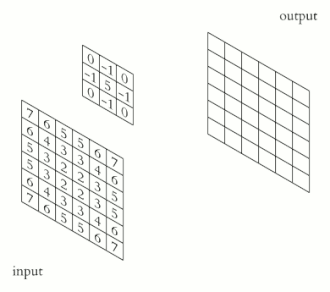

#### Convolución vs. correlación cruzada

En la definición anterior el kernel se **voltea** (flip) antes de multiplicar. Si no lo volteamos, la operación se llama **correlación cruzada**:

$$
(K \star X)(i, j) = \sum_{m}\sum_{n} k_{m,n}\, x_{i+m,\, j+n}
$$

Las dos operaciones difieren solo en la orientación del kernel: correlacionar con $K$ es lo mismo que convolucionar con $K$ volteado.

**Importante para lo que sigue:** las capas `Conv2D` de Keras y `nn.Conv2d` de PyTorch calculan en realidad *correlación cruzada*, aunque se llamen "convolución". Como los pesos del kernel se **aprenden**, la red simplemente aprendería el kernel volteado: la distinción es irrelevante para el entrenamiento. Sí importa al comparar con `scipy.signal.convolve2d` o al interpretar un kernel aprendido.

In [ ]:
from scipy.signal import convolve2d, correlate2d

conv = convolve2d(image, kernel, mode='same')     # kernel volteado
corr = correlate2d(image, kernel, mode='same')    # kernel sin voltear

print("Convolución (píxel central):", conv[2, 2])
print("Correlación (píxel central):", corr[2, 2])
print("¿Correlación == convolución con el kernel volteado?",
      np.array_equal(corr, convolve2d(image, kernel[::-1, ::-1], mode='same')))

In [ ]:
# Lo que hace un framework de deep learning: correlación cruzada
import torch
import torch.nn.functional as F

x_t = torch.tensor(image, dtype=torch.float32)[None, None]    # (N=1, C=1, H, W)
k_t = torch.tensor(kernel, dtype=torch.float32)[None, None]   # (C_out=1, C_in=1, K, K)

salida_torch = F.conv2d(x_t, k_t, padding=1)[0, 0].numpy()
print("¿F.conv2d == correlate2d?", np.array_equal(salida_torch, corr))
print("¿F.conv2d == convolve2d? ", np.array_equal(salida_torch, conv))

### 1.4.b Filtros (kernel) útiles (ejemplos)

#### Operador Sobel

Detección de bordes

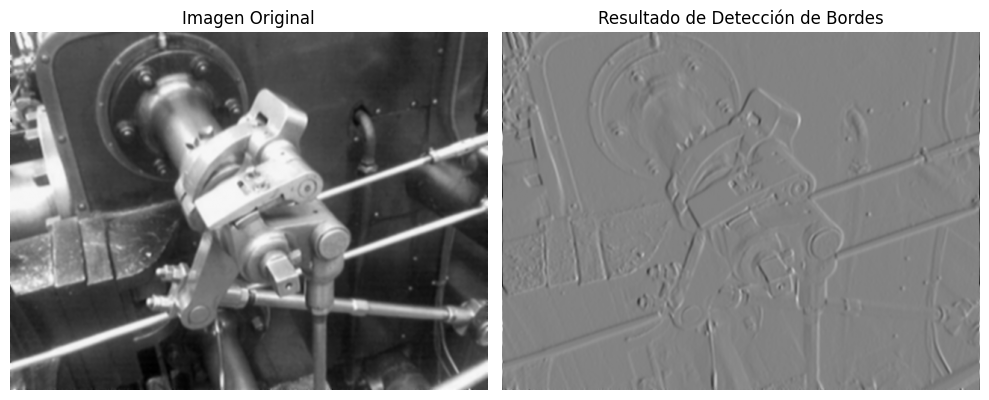

In [ ]:
import numpy as np
from scipy.signal import convolve2d
from PIL import Image
import matplotlib.pyplot as plt

# Paso 1: Cargar la imagen y convertirla a escala de grises
image_path = 'motors.png'  # Actualiza esto a la ruta de tu imagen
image = Image.open(image_path).convert('L')  # Convertir a escala de grises usando PIL
image_array = np.array(image)

# Paso 2: Definir un kernel para la detección de bordes (operador Sobel)
kernel = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
])

# kernel = np.array([
 #    [a, b, c],
#    [d, e, f],
#    [g, h, i]
#])

# Paso 3: Aplicar la operación de convolución
convolved_image = convolve2d(image_array, kernel, mode='same', boundary='wrap')

# Paso 4: Mostrar las imágenes original y procesada
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image_array, cmap='gray')
ax[0].set_title('Imagen Original')
ax[0].axis('off')

ax[1].imshow(convolved_image, cmap='gray')
ax[1].set_title('Resultado de Detección de Bordes')
ax[1].axis('off')

plt.tight_layout()
plt.show()


#### Realce (sharpen)

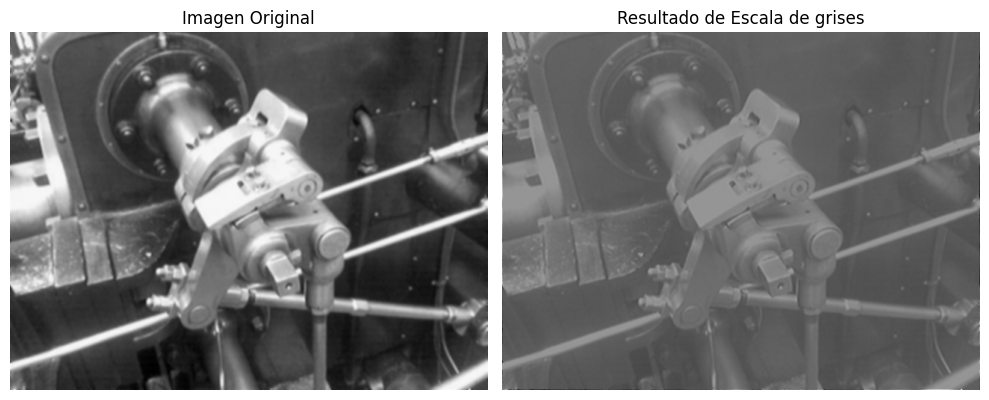

In [ ]:
import numpy as np
from scipy.signal import convolve2d
from PIL import Image
import matplotlib.pyplot as plt

# Paso 1: Cargar la imagen y convertirla a escala de grises
image_path = 'motors.png'  # Actualiza esto a la ruta de tu imagen
image = Image.open(image_path).convert('L')  # Convertir a escala de grises usando PIL
image_array = np.array(image)

# Paso 2: Definir un kernel de realce (sharpen)
kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
])

# Paso 3: Aplicar la operación de convolución
convolved_image = convolve2d(image_array, kernel, mode='same', boundary='wrap')

# Paso 4: Mostrar las imágenes original y procesada
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(image_array, cmap='gray')
ax[0].set_title('Imagen Original')
ax[0].axis('off')

ax[1].imshow(convolved_image, cmap='gray')
ax[1].set_title('Resultado de Realce (sharpen)')
ax[1].axis('off')

plt.tight_layout()
plt.show()


#### Blur



In [ ]:
motors = cv.imread('motors.png')
kernel2 = np.ones((5, 5), np.float32) / 25
blurred = cv.filter2D(src=motors, ddepth=-1, kernel=kernel2)

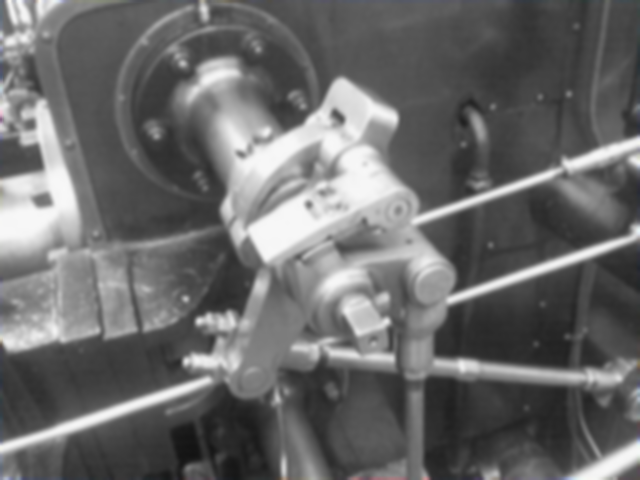

In [ ]:
cv2_imshow(blurred)

Sin embargo, la mayoría de operadores están definidos ya en los frameworks

In [ ]:
blurred_2 = cv.blur(src=motors, ksize=(5,5))

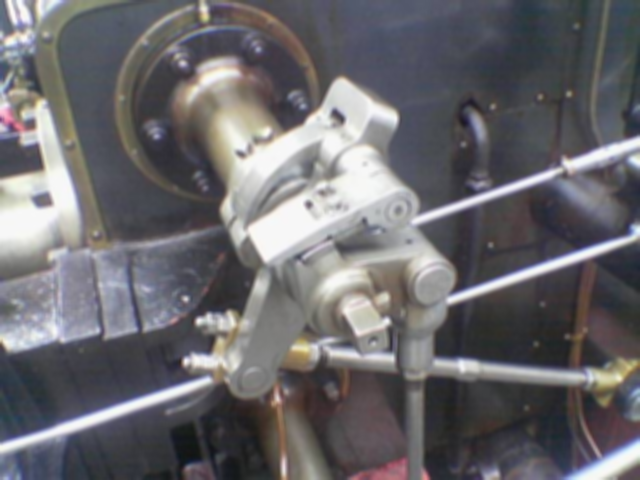

In [ ]:
cv2_imshow(blurred_2)

#### Otros operadores (Kernels)

https://en.wikipedia.org/wiki/Kernel_(image_processing)

# 2 Redes Neuronales Convolucionales

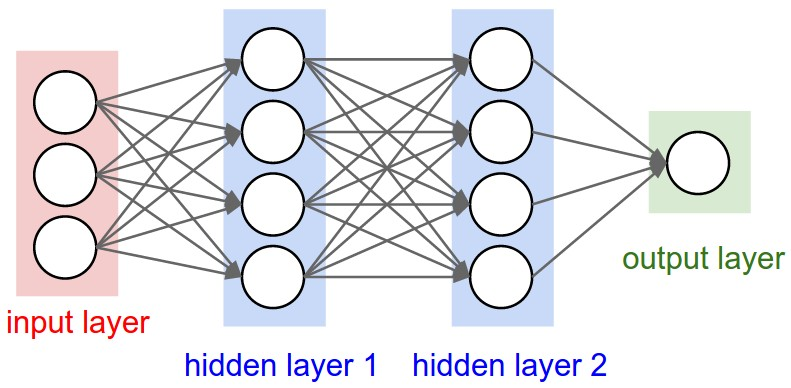

## 2.1 Motivación

### 2.1.a Dimensionalidad de las imágenes y repercusión en la red

- Las redes convencionales reciben como entrada un vector y aplican transformaciones por cada capa oculta.
- En la última capa, normalmente llamada capa de salida, decidimos el tipo de aprendizaje: regresión o clasificación.
- Las redes neuronales convencionales no escalan bien para imágenes de alta resolución: con una imagen $32 \times 32 \times 3$ **cada neurona** de la primera capa oculta tiene $3072$ pesos. Si la imagen es $500 \times 500 \times 3$, cada neurona tiene $750.000$ pesos; con 512 neuronas ocultas ya son $384$ millones de parámetros en una sola capa.
- El número de parámetros crece linealmente con la cantidad de píxeles, mientras que en una capa convolucional (lo veremos en 2.2) **no depende de la resolución**.

Resumen:

**La cantidad de parámetros a entrenar en redes lineales** implica problemas prácticos sobre cantidad de datos, memoria y si es posible o no entrenarlas.

In [ ]:
# Parámetros de la PRIMERA capa: lineal vs. convolucional, en función de la resolución
def params_lineal(H, W, C, n_neuronas):
    return (H * W * C) * n_neuronas + n_neuronas

def params_conv(C_in, C_out, K):
    return C_in * C_out * K * K + C_out       # no depende de H ni de W

for (H, W, C) in [(28, 28, 1), (32, 32, 3), (224, 224, 3), (500, 500, 3)]:
    print(f"{H}x{W}x{C}: lineal (512 neuronas) = {params_lineal(H, W, C, 512):>13,} | "
          f"conv (32 kernels 3x3) = {params_conv(C, 32, 3):,}")

### 2.1.b Explotando la noción de localidad

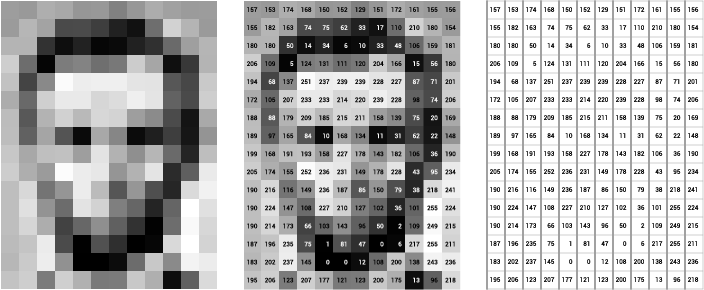

*  Los píxeles vecinos están altamente correlacionados: la información relevante (bordes, texturas, formas) es **local** y se repite en distintas posiciones de la imagen.
*  Una red completamente conectada trata cada píxel como una variable independiente. Si aplicamos una **misma permutación fija** a los píxeles de todas las imágenes, la FNN aprende exactamente igual: para ella el orden de las entradas no significa nada. Esto muestra que no explota la estructura espacial y debe *descubrirla* a partir de los datos.
*  Una red convolucional, en cambio, sí depende del orden: sus kernels operan sobre vecindarios. Comprobaremos esto empíricamente al final del notebook (experimento de píxeles permutados).

### 2.1.c Una red con imágenes debería ser estable ante dos tipos de transformaciones

1.  Invarianza: Una función $f$ es invariante a la transformación $t$ si: $$f(t(x))=f(x)$$

Es decir, la transformación no afecta la salida de la función aplicada



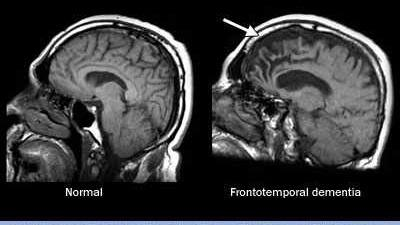

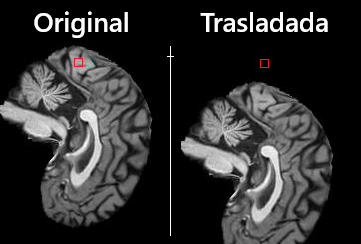

El diagnóstico debería ser el mismo: $f(MRI)=\text{ FTD}$

2.  Equivarianza: Una función $f$ es equivariante a la transformación $t$ si: $$f(t(x))=t(f(x))$$

Es decir, la transformación de la función es lo mismo que la función de la transformación.



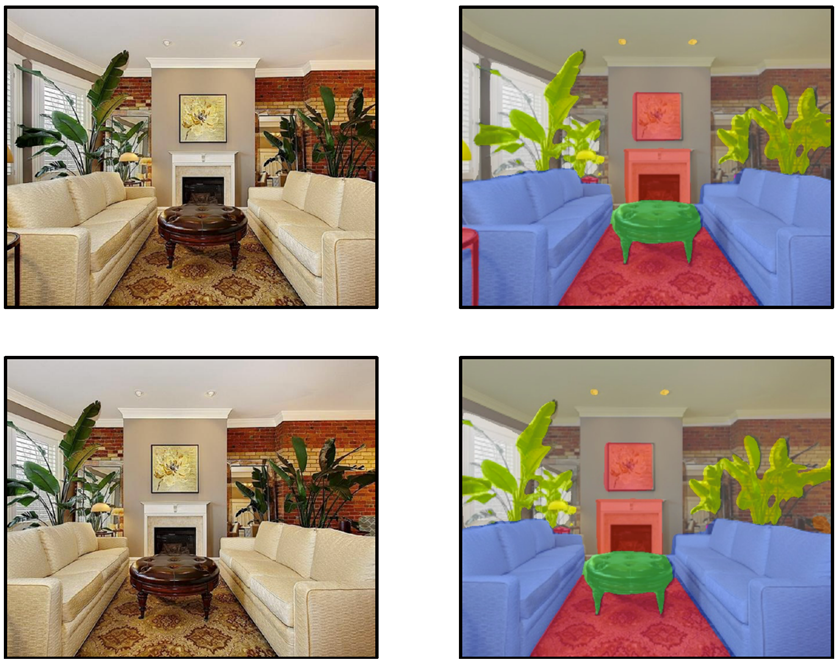

En el contexto médico

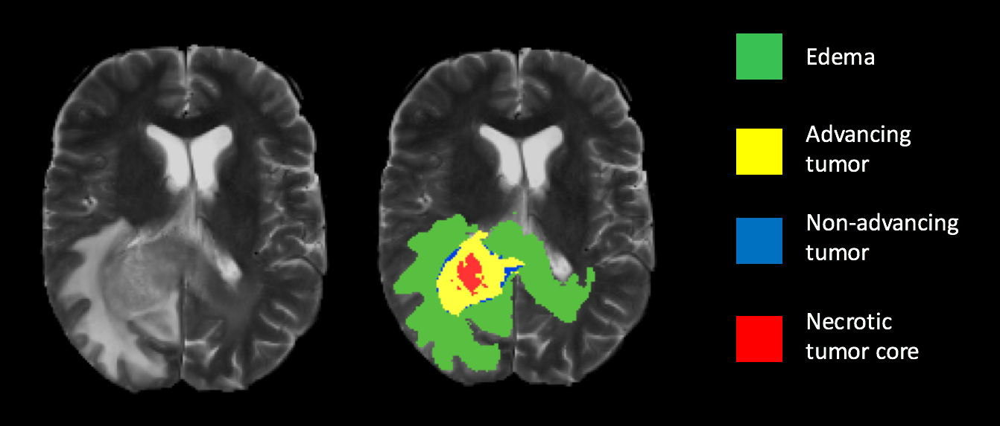

**Conexión con las capas que veremos:** una capa convolucional es (aproximadamente) *equivariante* a traslaciones: si desplazamos la entrada, el mapa de características se desplaza igual. Las capas de *pooling* y la capa lineal final agregan la información espacial y convierten esa equivarianza en una *invarianza* aproximada: la clase predicha no debería cambiar si el objeto se mueve unos píxeles. Una red completamente conectada no tiene ninguna de las dos propiedades por construcción; tendría que aprenderlas a partir de los datos.

## 2.2 Convolución en Redes Neuronales Convolucionales

### 2.2.a Ejemplo: Caso 1D

- Vector de entrada $\mathbf{x}$ :

$$
\mathbf{x}=\left[x_1, x_2, \ldots, x_I\right]
$$

- La salida es de nuevo una combinación lineal:

$$
z_i=\omega_1 x_{i-1}+\omega_2 x_i+\omega_3 x_{i+1}
$$

- Filtro o Kernel de la convolución:

$$
\boldsymbol{\omega}=\left[\omega_1, \omega_2, \omega_3\right]^T \quad \text { Kernel size }=3
$$


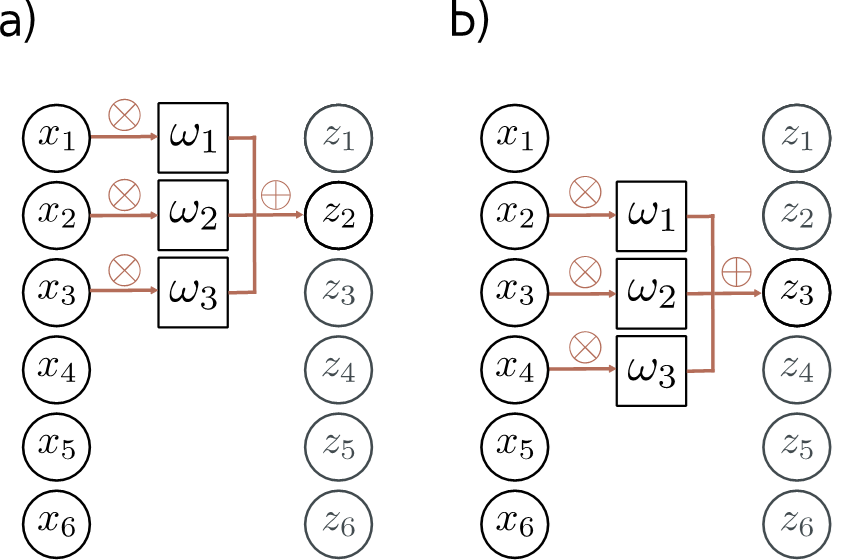

### Definición

Una red convolucional igualmente está compuesta por capas. Cada capa tendrá distinta funcionalidad pero tienen un objetivo en común: transformar una entrada de dimensión $D_{in}$ en una salida de dimensión $D_{out}$ con alguna función diferenciable que puede tener o no parámetros.

- Las neuronas en cada capa están ordenadas en tres dimensiones: ancho, alto y profundidad.
- Las capas intermedias pueden ser:
  1. Capas convolucionales
  1. Capas de pooling
  1. Capas de normalización
  1. Capas completamente conectadas (Estas las conocemos) (Linear)

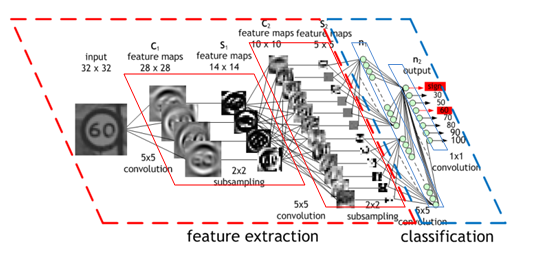

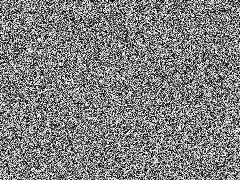

### Capas de convolución

Aplicando el concepto de convolución, buscamos entrenar filtros dependiendo del los parámetros que queramos usar.

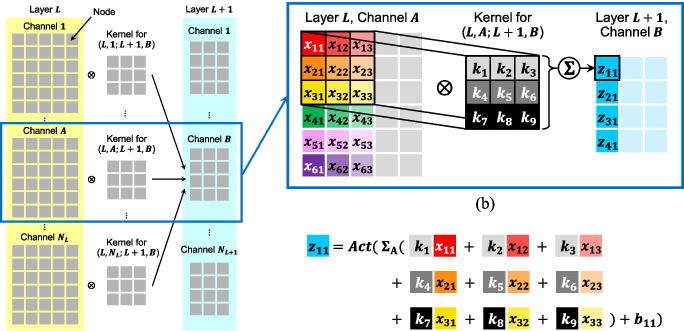

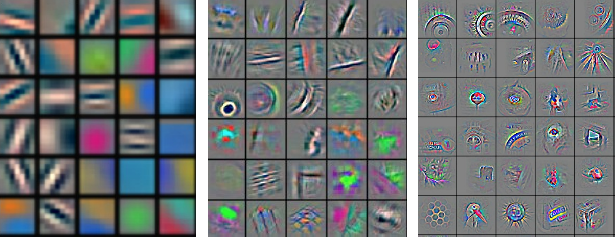

In [ ]:
from IPython.display import IFrame
IFrame('https://cs231n.github.io/assets/conv-demo/index.html', width=700, height=700)

### Padding,  Stride, tamaño del kernel y dilatación

**Padding**: agregamos valores (por lo general 0) alrededor de la entrada para poder calcular la convolución también en los bordes y controlar el tamaño de la salida. `padding='valid'` no agrega nada (la salida se encoge); `padding='same'` agrega lo necesario para que, con stride 1, la salida tenga el mismo tamaño que la entrada.

**Stride**: el kernel se desplaza $S$ posiciones entre una salida y la siguiente, en lugar de 1. Con $S = 2$ la salida tiene aproximadamente la mitad del tamaño: es una forma de reducir dimensionalidad dentro de la propia convolución.

**Tamaño del kernel**: incrementa la dimensión del kernel para evaluar más píxeles/vóxeles a la vez, es decir, trabajar con un área más grande. El costo en parámetros crece con $K^2$.

**Dilatación**: intercala huecos (pesos fijos en cero) entre los elementos del kernel. Un kernel $3 \times 3$ con dilatación 2 cubre un área $5 \times 5$ con solo 9 parámetros: amplía el área observada sin aumentar parámetros ni reducir la resolución.

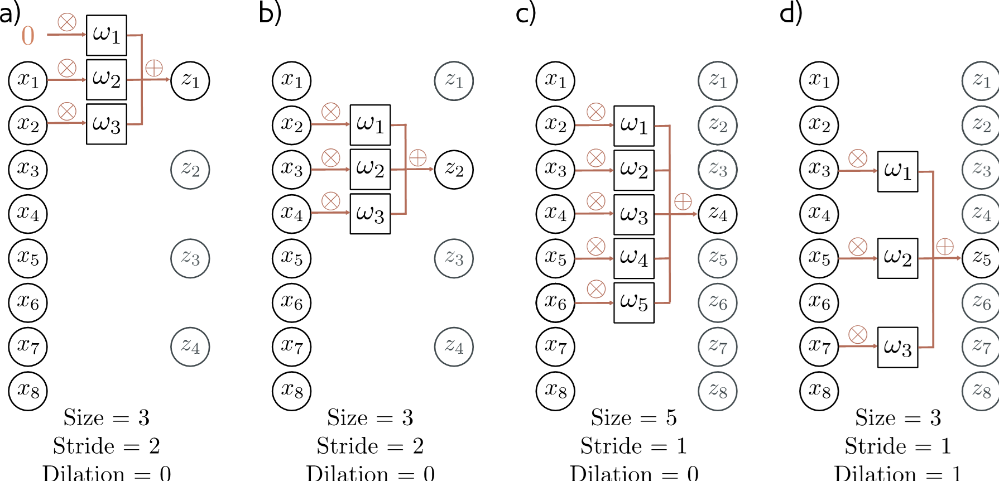

### Tamaño de la salida

Para una entrada de tamaño $I$ (por lado), kernel $K$, stride $S$, padding $P$ y dilatación $D$, la salida tiene tamaño:

$$
O = \left\lfloor \frac{I + 2P - D\,(K-1) - 1}{S} \right\rfloor + 1
$$

Casos frecuentes ($D = 1$):
- `padding='valid'` ($P=0$), $S=1$: $O = I - K + 1$ (la imagen se encoge $K-1$ píxeles por capa).
- `padding='same'` en Keras: el framework elige $P$ para que $O = \lceil I / S \rceil$. Con $S = 1$ la salida conserva el tamaño; con $S = 2$ se reduce a la mitad.
- Pooling $2 \times 2$ con stride 2: $O = \lfloor I / 2 \rfloor$.

Esta fórmula es la que usaremos para leer la columna *Output Shape* de `model.summary()`.

In [ ]:
import math

def tamano_salida(I, K, S=1, P=0, D=1):
    return (I + 2*P - D*(K - 1) - 1) // S + 1

print("28x28, conv 3x3, stride 1, padding 1 ('same') :", tamano_salida(28, 3, S=1, P=1))
print("28x28, conv 3x3, stride 2, padding 1 ('same') :", tamano_salida(28, 3, S=2, P=1), "= ceil(28/2) =", math.ceil(28/2))
print("28x28, conv 3x3, sin padding ('valid')        :", tamano_salida(28, 3))
print("7x7,   max-pool 2x2, stride 2                 :", tamano_salida(7, 2, S=2))
print("28x28, conv 3x3, dilatación 2, sin padding    :", tamano_salida(28, 3, D=2))

## 2.3 Campo receptivo

El **campo receptivo** de una neurona es la región de la imagen de entrada que influye en su valor. En la primera capa es $K \times K$; al apilar capas crece: dos convoluciones $3 \times 3$ consecutivas ven una región $5 \times 5$, tres ven $7 \times 7$, y cada capa con stride o pooling lo multiplica. Por eso las CNN modernas usan kernels pequeños ($3 \times 3$) apilados en lugar de kernels grandes: cubren la misma área con menos parámetros ($2 \cdot 9 = 18 < 25$) y con una no linealidad adicional entre medio.

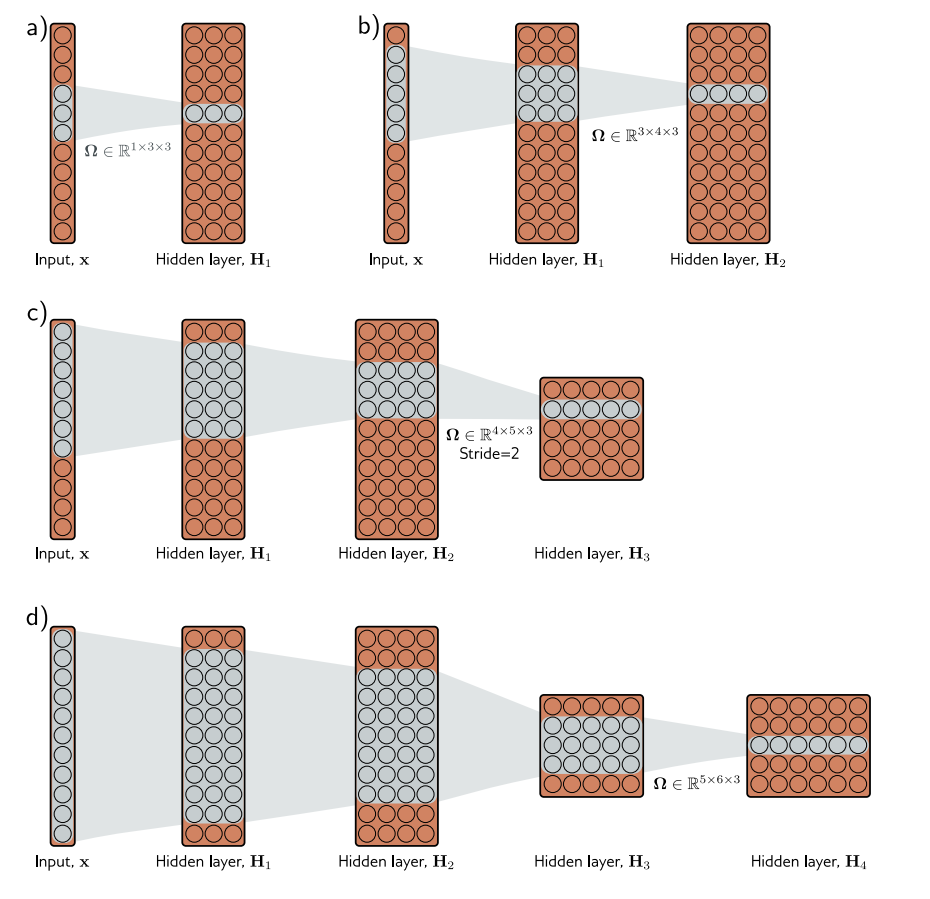

## 2.4 Las CNN son casos especiales de FNN

### 2.4.1 Cómo cambian las capas?

Tomando en cuenta la definición, podemos escribir una capa convolucional como: $$
\begin{aligned}
h_i & =\mathrm{a}\left[\beta+\omega_1 x_{i-1}+\omega_2 x_i+\omega_3 x_{i+1}\right] \\
& =\mathrm{a}\left[\beta+\sum_{j=1}^3 \omega_j x_{i+j-2}\right]
\end{aligned}
$$

Comparada a una capa lineal, qué cambia?

$$
h_i=\mathrm{a}\left[\beta_i+\sum_{j=1}^D \omega_{i j} x_j\right]
$$

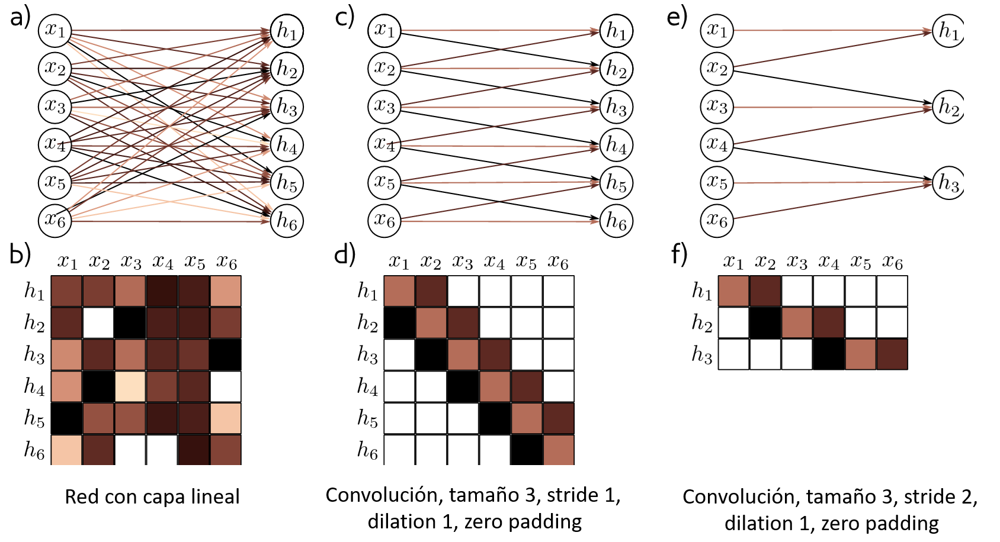

Tres cosas cambian:

1. **Conectividad local**: $h_i$ depende solo de un vecindario de tamaño $K$ ($x_{i-1}, x_i, x_{i+1}$), no de las $D$ entradas.
1. **Pesos compartidos**: los mismos $\omega_1, \omega_2, \omega_3$ se usan en todas las posiciones $i$. En la capa lineal cada salida $h_i$ tiene su propia fila de pesos $\omega_{ij}$.
1. **Un solo sesgo** $\beta$ por kernel, en lugar de un $\beta_i$ por neurona.

| | Capa lineal (`Dense` / `Linear`) | Capa convolucional (`Conv2D`) |
|---|---|---|
| Parámetros | $D_{in} \cdot D_{out} + D_{out}$ | $C_{in} \cdot C_{out} \cdot K^2 + C_{out}$ |
| ¿Depende de la resolución? | Sí | No |
| Conectividad | Global | Local (vecindario $K \times K$) |
| Pesos | Distintos en cada posición | Compartidos entre posiciones |
| Equivariante a traslación | No | Sí |
| Forma de la salida | Vector | Tensor $H' \times W' \times C_{out}$ |

Una consecuencia importante: **una capa convolucional es un caso particular de capa lineal**. Se puede escribir como $\mathbf{h} = a[\mathbf{W}\mathbf{x} + \boldsymbol{\beta}]$ donde $\mathbf{W}$ es una matriz con estructura de bandas (Toeplitz) en la que casi todas las entradas son cero y las no nulas están *atadas* entre sí. La CNN no es "más expresiva" que la FNN: es una FNN con una restricción fuerte (un *sesgo inductivo*) que encaja con la estructura de las imágenes y reduce drásticamente los parámetros a estimar.

In [ ]:
# Una convolución 1D escrita como producto matriz-vector
x = np.array([1., 2., 3., 4., 5., 6., 7., 8.])   # entrada, D = 8
w = np.array([-1., 0., 1.])                      # kernel, K = 3
D, K = len(x), len(w)
O = D - K + 1                                    # salida sin padding

W = np.zeros((O, D))
for i in range(O):
    W[i, i:i+K] = w                              # la misma fila, desplazada

print(W)
print("W @ x        :", W @ x)
print("np.correlate :", np.correlate(x, w, mode='valid'))
print(f"Parámetros libres: conv = {K} | capa lineal {O}x{D} = {W.size}")

## 2.5 Canales

1.   La capa convolucional toma en cuenta la información local de los píxeles/vóxeles
2.   Aplicamos una función de activación
3. Sin duda perdemos información. Qué hacer?



1. Aplicamos varios kernels distintos sobre la misma entrada. Cada kernel produce un **mapa de características** (*feature map*); el conjunto de mapas forma los **canales** de salida de la capa.
1. Cada kernel puede especializarse en un patrón distinto (bordes verticales, horizontales, texturas...), de modo que la información que pierde uno la conserva otro.

### Dos canales de salida, un canal de entrada

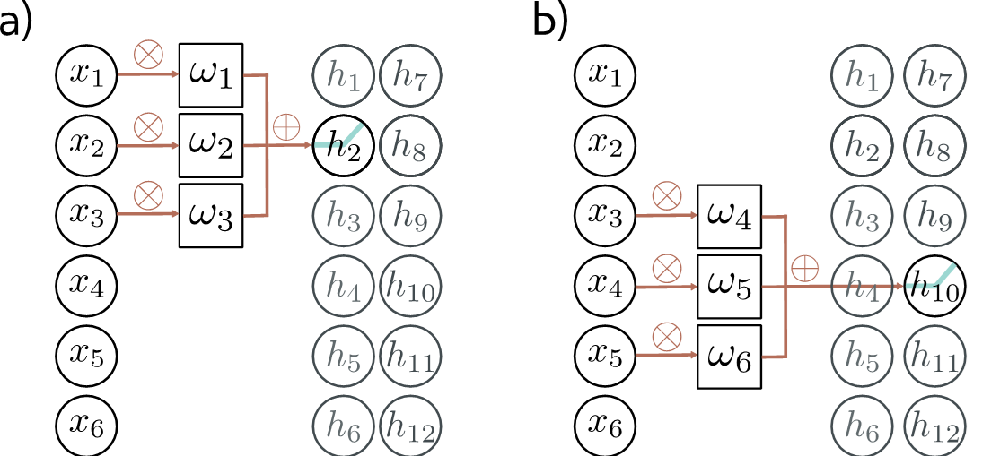

### Dos canales de entrada, un canal de salida

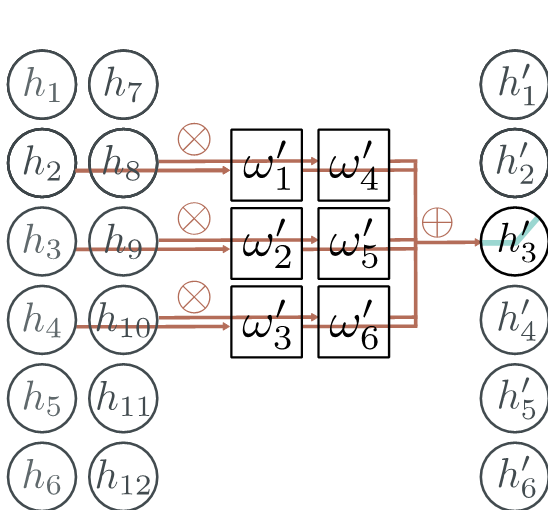

## 2.6 Cantidad de parámetros?

- Si tenemos $C_i$ canales de entrada con tamaño de kernel $K$

$$
\boldsymbol{\Omega} \in \mathbb{R}^{C_i \times K}
$$


$$
\boldsymbol{\beta} \in \mathbb{R}
$$

- Si tenemos $C_i$ canales de entrada con tamaño de kernel $K$ y $C_o$ canales de salida
$$
\boldsymbol{\Omega} \in \mathbb{R}^{C_i \times C_o \times K} \quad \boldsymbol{\beta} \in \mathbb{R}^{C_o}
$$


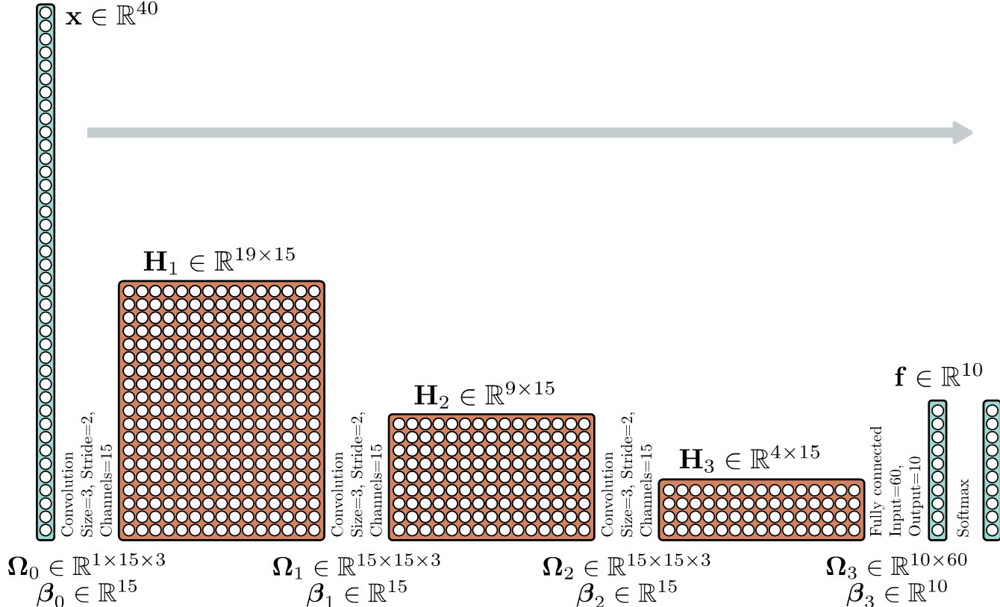

## 2.7 Convolución en 2D

- Suma pondereda sobre una región $\mathrm{K} \times \mathrm{K}$
- Pesos de dimensión $\mathrm{K} \times \mathrm{K}$
- Agregar a una red convolucional agregando un posible sesgo $\beta$ y una función de activación $a$.

$$
h_{i, j}=\mathrm{a}\left[\beta+\sum_{m=1}^3 \sum_{n=1}^3 \omega_{m, n} x_{i+m-2, j+n-2}\right]
$$


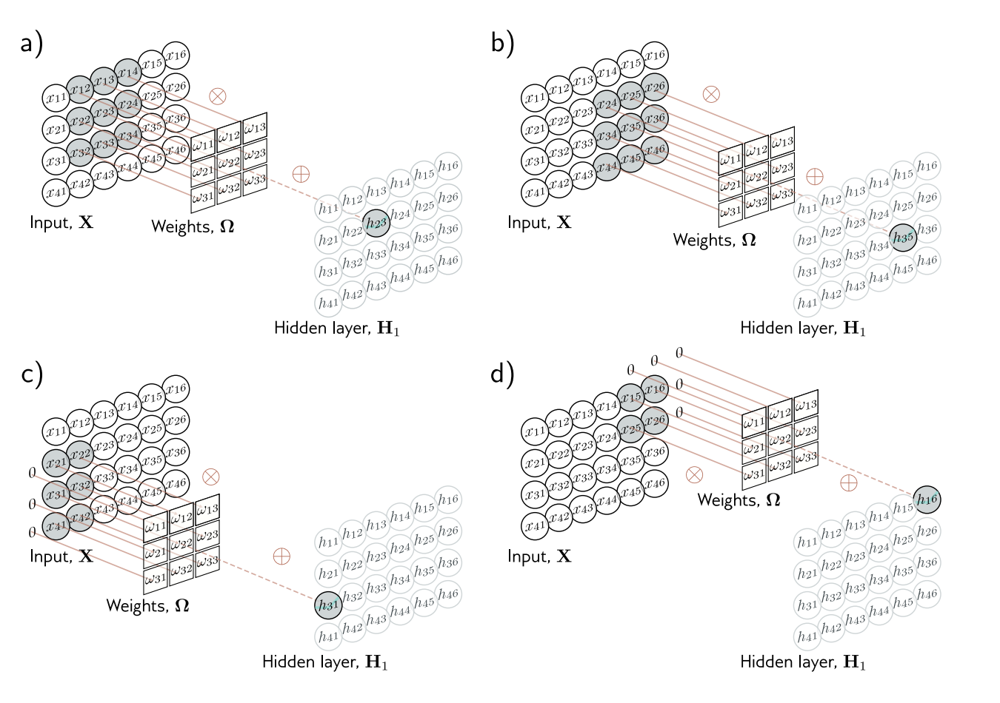

Convolución aplicada a una imagen

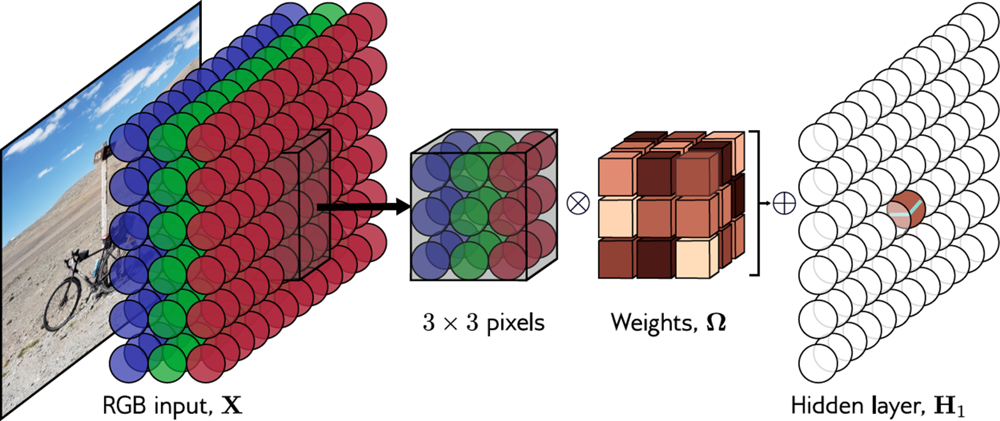

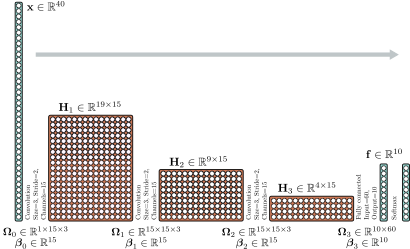

- Si tenemos $C_i$ canales de entrada y dimensión de kernel $\mathrm{K} \times \mathrm{K}$

$$
\boldsymbol{\omega} \in \mathbb{R}^{C_i \times K \times K} \quad \boldsymbol{\beta} \in \mathbb{R}
$$


- Si tenemos $C_i$ canales de entrada, dimensión de kernel $\mathrm{K} \times \mathrm{K}$ y   $C_o$ canales de salida

$$
\boldsymbol{\omega} \in \mathbb{R}^{C_i \times C_o \times K \times K} \quad \boldsymbol{\beta} \in \mathbb{R}^{C_o}
$$


In [ ]:
# Verificación con las tres capas de la CNN que entrenaremos más adelante
def parametros_conv2d(C_in, C_out, K):
    return C_in * C_out * K * K + C_out

for C_in, C_out in [(1, 32), (32, 64), (64, 128)]:
    print(f"Conv2D({C_in:>3} -> {C_out:>3}, 3x3): {parametros_conv2d(C_in, C_out, 3):>7,} parámetros")

## 2.8 Downsampling - Capas de Pooling

Es común insertar periódicamente una capa de Pooling entre capas Conv sucesivas en una arquitectura ConvNet.

- Su función es reducir progresivamente el tamaño espacial de la representación. La capa de pooling **no tiene parámetros**: lo que reduce es el costo computacional de las capas siguientes y el número de parámetros de la capa lineal que viene después del `Flatten`. De paso aporta cierta invarianza a traslaciones pequeñas y ayuda a controlar el sobreajuste.
- Las dos variantes usuales son **max pooling** (conserva el valor máximo de cada ventana) y **average pooling** (el promedio). Max pooling es la más común en clasificación porque conserva las activaciones más fuertes.

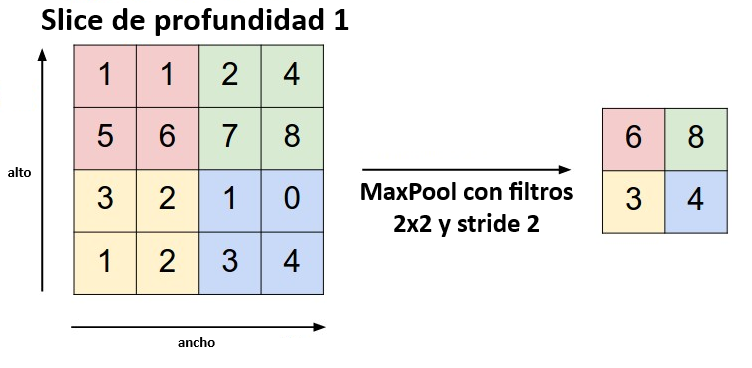

Ejemplo:

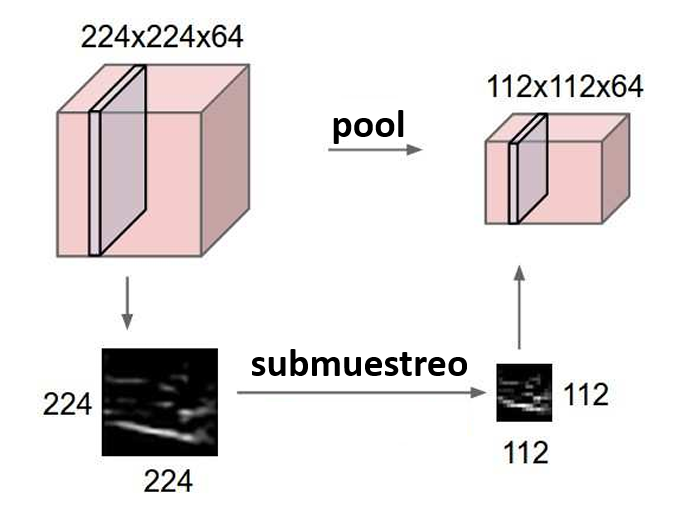

Lo que sucede entonces es que las capas convolucionales son reducidas en las de pooling.

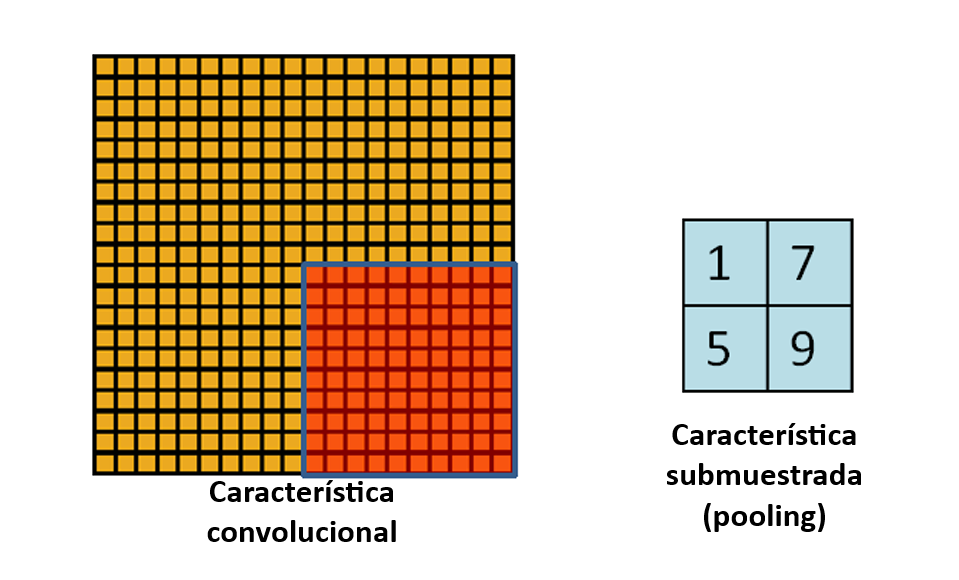

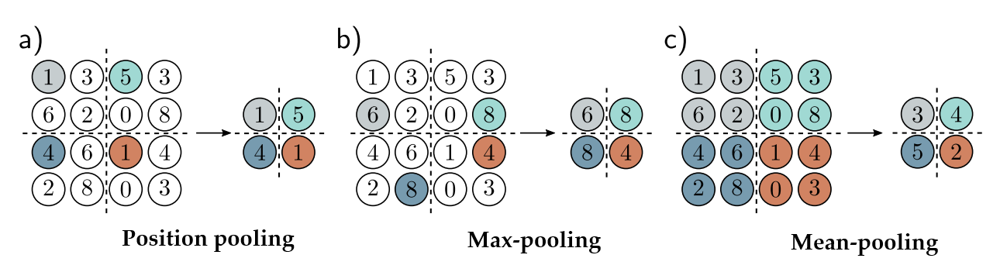

### 2.8.1 Adaptive pooling

El pooling clásico fija el tamaño de la ventana y el stride, así que el tamaño de la salida depende del de la entrada. El **adaptive pooling** invierte la lógica: fijamos el tamaño de salida deseado (p. ej. $7 \times 7$ o $1 \times 1$) y el framework calcula la ventana necesaria. Es lo que permite que una misma red acepte imágenes de distintas resoluciones y siga entregando un vector de tamaño fijo a la capa lineal.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

class ImagePooling(nn.Module):
    def __init__(self):
        super(ImagePooling, self).__init__()
        self.max_pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.avg_pool = nn.AvgPool2d(kernel_size=2, stride=2)
        self.adaptive_avg_pool = nn.AdaptiveAvgPool2d((64, 64))
        self.adaptive_max_pool = nn.AdaptiveMaxPool2d((32, 32))

    def forward(self, x):
        max_pooled = self.max_pool(x)
        avg_pooled = self.avg_pool(x)
        adaptive_avg_pooled = self.adaptive_avg_pool(x)
        adaptive_max_pooled = self.adaptive_max_pool(x)

        return {
            'original': x,
            'max_pool': max_pooled,
            'avg_pool': avg_pooled,
            'adaptive_avg_pool': adaptive_avg_pooled,
            'adaptive_max_pool': adaptive_max_pooled
        }

def load_image(image_path, target_size=(224, 224)):
    image = Image.open(image_path)

    if image.mode != 'RGB':
        image = image.convert('RGB')

    transform = transforms.Compose([
        transforms.Resize(target_size),
        transforms.ToTensor(),
    ])

    image_tensor = transform(image)

    # Shape debería ser: (1, C, H, W)
    image_tensor = image_tensor.unsqueeze(0)

    return image_tensor, image

def tensor_to_image(tensor):
    if tensor.dim() == 4:
        tensor = tensor.squeeze(0)

    if tensor.shape[0] == 3:
        img = tensor.permute(1, 2, 0).detach().numpy()
    else:
        img = tensor.squeeze().detach().numpy()

    img = np.clip(img, 0, 1)

    return img

def display_pooling_results(image_path):
    input_tensor, original_pil = load_image(image_path)

    pooling_model = ImagePooling()

    with torch.no_grad():
        results = pooling_model(input_tensor)

    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    fig.suptitle('Operaciones de Pooling en la imagen original', fontsize=16, fontweight='bold')

    operations = [
        ('original', 'Imagen original'),
        ('max_pool', 'Max Pooling (2x2)'),
        ('avg_pool', 'Average Pooling (2x2)'),
        ('adaptive_avg_pool', 'Adaptive Avg Pool (64x64)'),
        ('adaptive_max_pool', 'Adaptive Max Pool (32x32)')
    ]

    for i, (op_key, title) in enumerate(operations):
        row = i // 3
        col = i % 3

        img_display = tensor_to_image(results[op_key])

        axes[row, col].imshow(img_display)
        axes[row, col].set_title(f'{title}\nShape: {results[op_key].shape[2:]}',
                                fontsize=12, fontweight='bold')
        axes[row, col].axis('off')

        for spine in axes[row, col].spines.values():
            spine.set_edgecolor('black')
            spine.set_linewidth(2)

    axes[1, 2].remove()

    plt.tight_layout()
    plt.show()

    return results

def compare_pooling_methods(image_path, kernel_size=4, stride=4):
    input_tensor, _ = load_image(image_path)

    max_pooled = F.max_pool2d(input_tensor, kernel_size=kernel_size, stride=stride)
    avg_pooled = F.avg_pool2d(input_tensor, kernel_size=kernel_size, stride=stride)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    fig.suptitle(f'Comparación de métodos de pooling para mismo tamaño de K (Kernel: {kernel_size}x{kernel_size})', fontsize=14, fontweight='bold')

    images = [
        (input_tensor, 'Original'),
        (max_pooled, 'Max Pooling'),
        (avg_pooled, 'Average Pooling')
    ]

    for i, (tensor, title) in enumerate(images):
        img_display = tensor_to_image(tensor)
        axes[i].imshow(img_display)
        axes[i].set_title(f'{title}\n{tensor.shape[2]}x{tensor.shape[3]}', fontweight='bold')
        axes[i].axis('off')

    plt.tight_layout()
    plt.show()

def show_different_kernel_sizes(image_path, kernel_sizes=[2, 4, 8, 16], stride_sizes=[2, 4, 8, 16]):
    input_tensor, _ = load_image(image_path)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle('Efecto para distintas dimensiones de kernel', fontsize=16, fontweight='bold')

    for i, (kernel_size, stride_size) in enumerate(zip(kernel_sizes, stride_sizes)):
        max_pooled = F.max_pool2d(input_tensor, kernel_size=kernel_size, stride=stride_size)
        max_img = tensor_to_image(max_pooled)

        axes[0, i].imshow(max_img)
        axes[0, i].set_title(f'Max Pool {kernel_size}x{stride_size}\n{max_pooled.shape[2]}x{max_pooled.shape[3]}',
                            fontweight='bold')
        axes[0, i].axis('off')

        avg_pooled = F.avg_pool2d(input_tensor, kernel_size=kernel_size, stride=stride_size)
        avg_img = tensor_to_image(avg_pooled)

        axes[1, i].imshow(avg_img)
        axes[1, i].set_title(f'Avg Pool {kernel_size}x{stride_size}\n{avg_pooled.shape[2]}x{avg_pooled.shape[3]}',
                            fontweight='bold')
        axes[1, i].axis('off')

    axes[0, 0].text(-0.1, 0.5, 'Max Pooling', transform=axes[0, 0].transAxes,
                    rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')
    axes[1, 0].text(-0.1, 0.5, 'Average Pooling', transform=axes[1, 0].transAxes,
                    rotation=90, va='center', ha='center', fontsize=14, fontweight='bold')

    plt.tight_layout()
    plt.show()

def demonstrate_adaptive_pooling(image_path, output_sizes=[(112, 112), (64, 64), (32, 32), (16, 16)]):
    input_tensor, _ = load_image(image_path)

    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    fig.suptitle('Adaptive Pooling - Diferentes salidas (shape)', fontsize=16, fontweight='bold')

    for i, output_size in enumerate(output_sizes):
        adaptive_max = F.adaptive_max_pool2d(input_tensor, output_size)
        max_img = tensor_to_image(adaptive_max)

        axes[0, i].imshow(max_img)
        axes[0, i].set_title(f'Adaptive Max\n{output_size[0]}x{output_size[1]}', fontweight='bold')
        axes[0, i].axis('off')

        adaptive_avg = F.adaptive_avg_pool2d(input_tensor, output_size)
        avg_img = tensor_to_image(adaptive_avg)

        axes[1, i].imshow(avg_img)
        axes[1, i].set_title(f'Adaptive Avg\n{output_size[0]}x{output_size[1]}', fontweight='bold')
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.show()

def show_original_image(image_path):
    original_pil = Image.open(image_path)

    plt.figure(figsize=(8, 6))
    plt.imshow(original_pil)
    plt.title(f'Imagen original\nDimensión: {original_pil.size}, Mode: {original_pil.mode}',
              fontsize=14, fontweight='bold')
    plt.axis('off')
    plt.show()

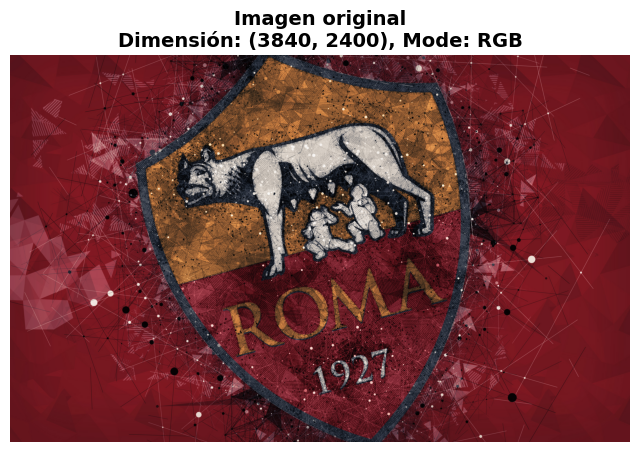

In [ ]:
show_original_image(image_path="972598.jpg")

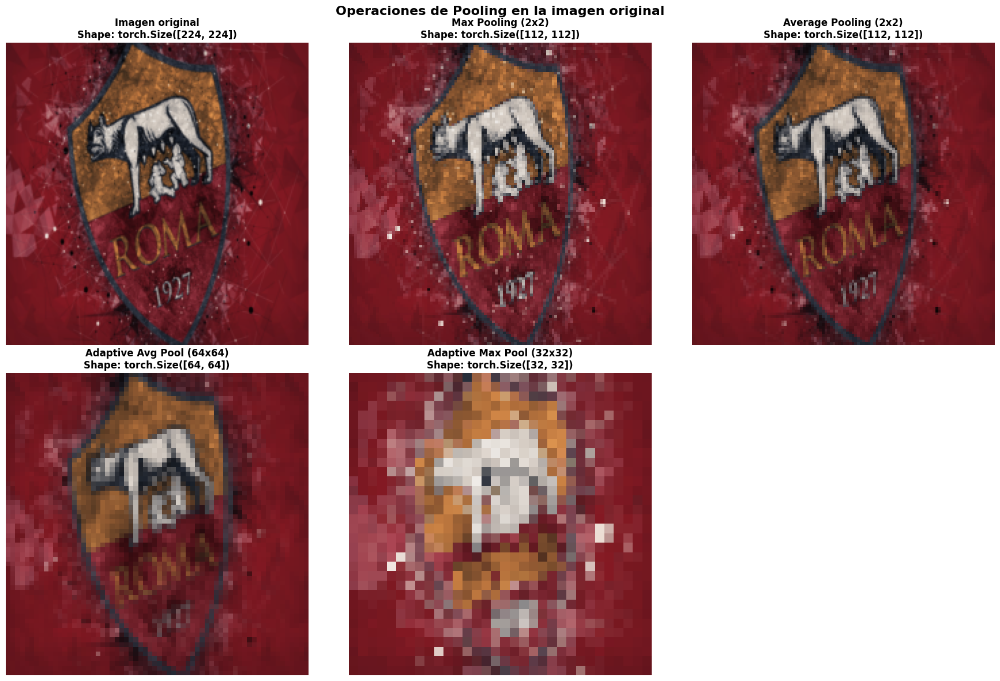

In [ ]:
results = display_pooling_results(image_path="972598.jpg")

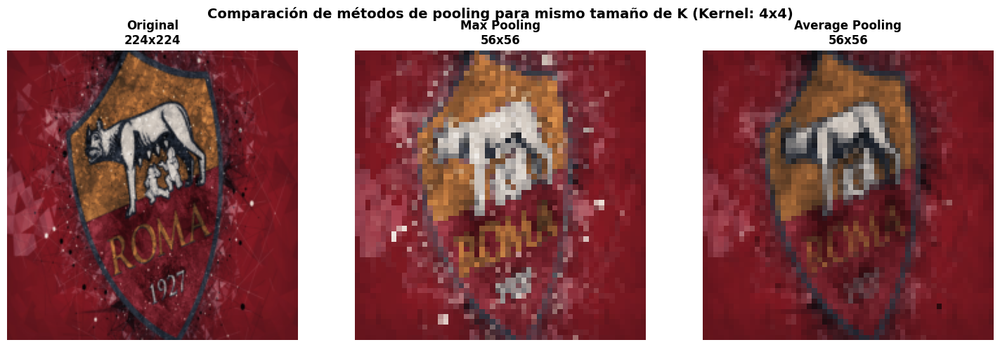

In [ ]:
compare_pooling_methods(image_path="972598.jpg")

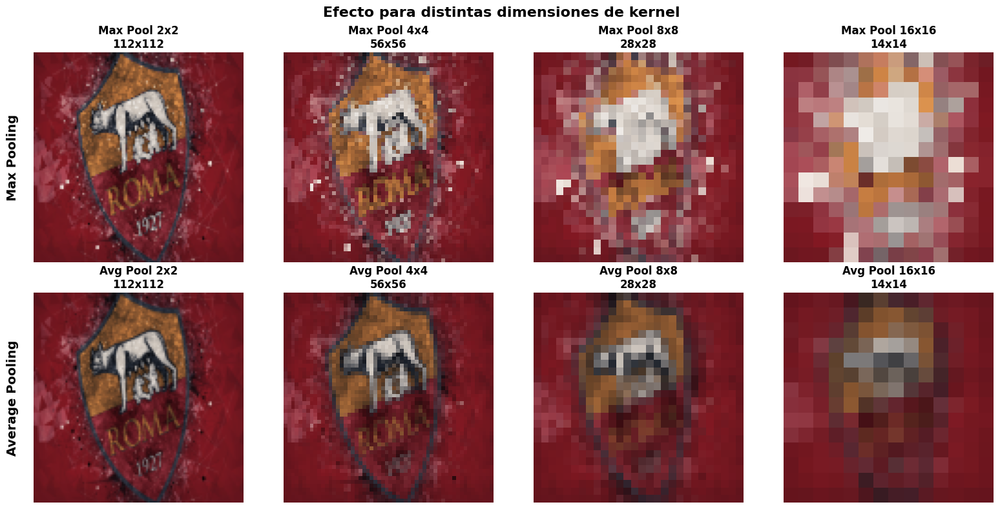

In [ ]:
show_different_kernel_sizes(image_path="972598.jpg")

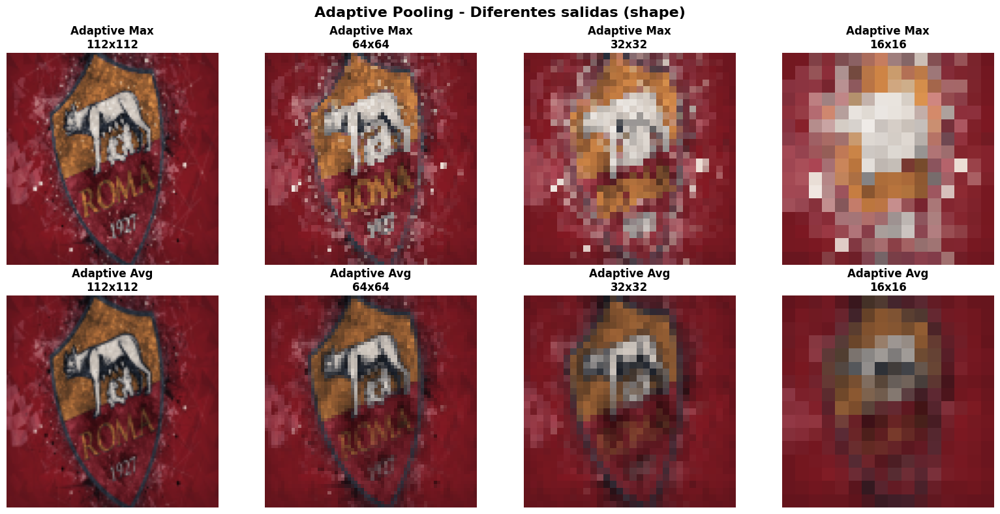

In [ ]:
demonstrate_adaptive_pooling(image_path="972598.jpg")

## 2.9 Del tensor a la capa lineal: Flatten vs. Global Average Pooling

Tras las capas convolucionales tenemos un tensor $H' \times W' \times C$ y la capa de salida necesita un vector. Hay dos formas habituales de hacer el puente:

1. **Flatten**: concatena todo en un vector de $H' \cdot W' \cdot C$ elementos. Es lo que hacen AlexNet y nuestra primera CNN. La capa `Dense` siguiente concentra la mayoría de los parámetros de la red y fija la resolución de entrada.
1. **Global Average Pooling (GAP)**: promedia cada canal sobre toda la extensión espacial y produce un vector de solo $C$ elementos (equivale a `AdaptiveAvgPool2d((1, 1))`). Reduce drásticamente los parámetros, admite cualquier resolución de entrada y actúa como regularizador. Es el estándar desde ResNet; lo usamos en el `mini_resnet` más abajo.

## 2.10 Upsampling

Para algunos modelos, es necesario revertir los procesos de reducción de dimensionalidad de la red para obtener las dimensiones originales.

### 2.10.1 Vecino más cercano (nearest neighbor)

Cada píxel se copia en un bloque $k \times k$ de la salida. Es el método más simple y no tiene parámetros.

### 2.10.2 Max-unpooling

Operación inversa al max pooling: se colocan los valores en las posiciones donde estaba el máximo (índices guardados durante el pooling) y el resto se rellena con ceros.

### 2.10.3 Interpolación bilineal

Usamos interpolación para "predecir" posibles valores en base a los que tenemos disponibles. A nivel de píxel e imágenes, es similar a aplicar un anti-aliasing.

#### Convolución transpuesta

A diferencia de los anteriores, tiene parámetros: aprende cómo distribuir cada valor de entrada sobre una ventana $K \times K$ de la salida (`ConvTranspose2d` / `Conv2DTranspose`). Es la opción típica en decodificadores de segmentación como U-Net.

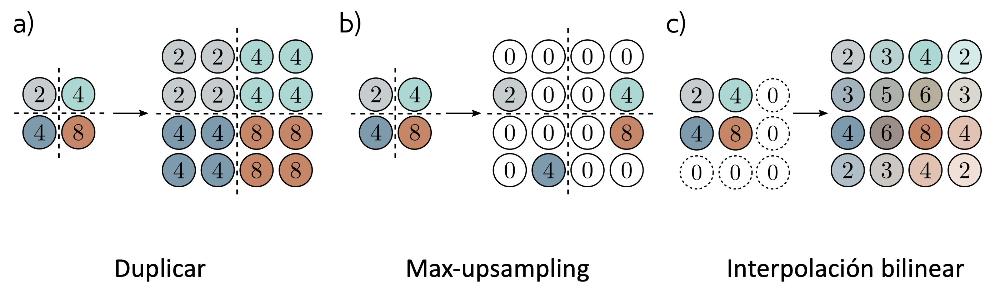

## 2.11 Convoluciones 1x1

En algnos casos, necesitamos modificar el número de canales distribuyendo la información obtenida en capas previas.

Para lograr esto, aplicamos convoluciones de 1 posición a lo largo de la dimensión de los canales. Seleccionaremos tantos kernels como canales necesitemos.

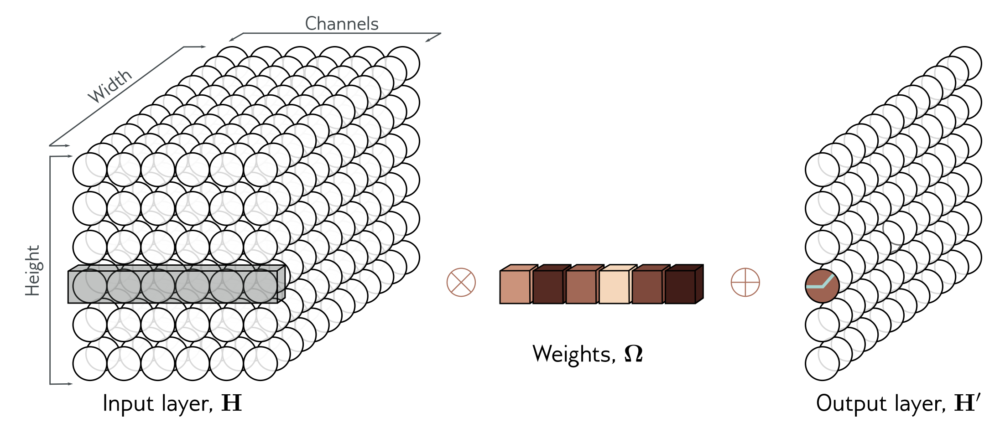

## 2.12 Capas de Normalización: [Batch Normalization](https://arxiv.org/abs/1502.03167)

Las activaciones intermedias cambian de distribución durante el entrenamiento, lo que obliga a usar learning rates pequeños. **Batch Normalization** (Ioffe y Szegedy, 2015) normaliza las activaciones de cada canal usando la media y la varianza del mini-batch, y luego deja que la red las re-escale:

$$
y=\frac{x-\mathrm{E}[x]}{\sqrt{\operatorname{Var}[x]+\epsilon}} \cdot \gamma+\beta
$$

de donde:

- En una capa convolucional, $\mathrm{E}[x]$ y $\operatorname{Var}[x]$ se calculan **por canal**, promediando sobre el batch y sobre las dimensiones espaciales.
- $\gamma$ y $\beta$ son vectores de parámetros que vamos a aprender, de dimensión $C$ (número de canales). Por defecto se inicializan en 1 y 0 respectivamente.
- Durante el entrenamiento se usan las estadísticas del batch; en inferencia se usan promedios móviles acumulados. Por eso es obligatorio alternar `model.train()` / `model.eval()` en PyTorch.
- Permite learning rates mayores, acelera la convergencia y tiene un efecto regularizador.

Su debilidad es la dependencia del tamaño del batch: con batches pequeños las estadísticas son ruidosas. **Layer Normalization** ([Ba et al., 2016](https://arxiv.org/abs/1607.06450)) y **Group Normalization** (Wu y He, 2018) evitan el problema normalizando cada ejemplo por separado, sin mirar al resto del batch. La figura siguiente compara sobre qué dimensiones se calculan las estadísticas en cada caso.

En los ejemplos usaremos BatchNorm; según las dimensiones de la entrada, la variante es

- [BatchNorm1d](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm1d.html)
- [BatchNorm2d](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html)
`





> Sergey Ioffe, Christian Szegedy: Batch Normalization: Accelerating Deep Network Training by Reducing Internal Covariate Shift [Paper](https://arxiv.org/abs/1502.03167)

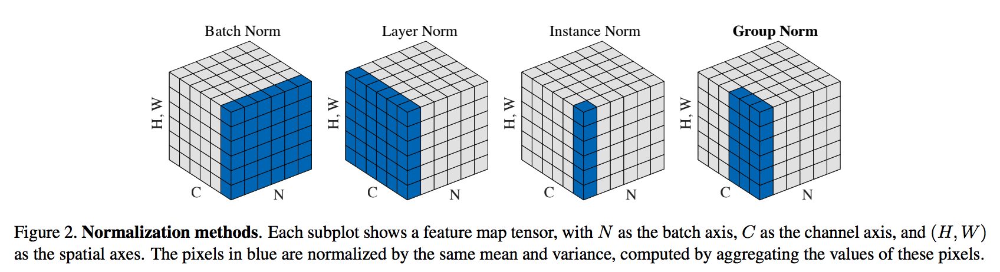

> Wu, Y. and He, K., 2018. Group normalization. arXiv preprint arXiv: 1803.08494. [paper](https://arxiv.org/abs/1803.08494)

### Normalización: en imágenes

#### Qué normalizamos?

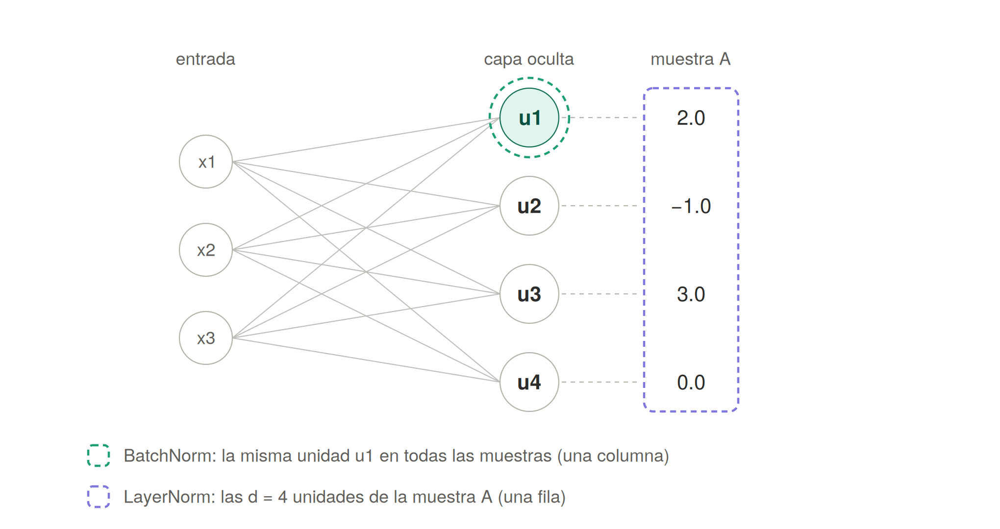

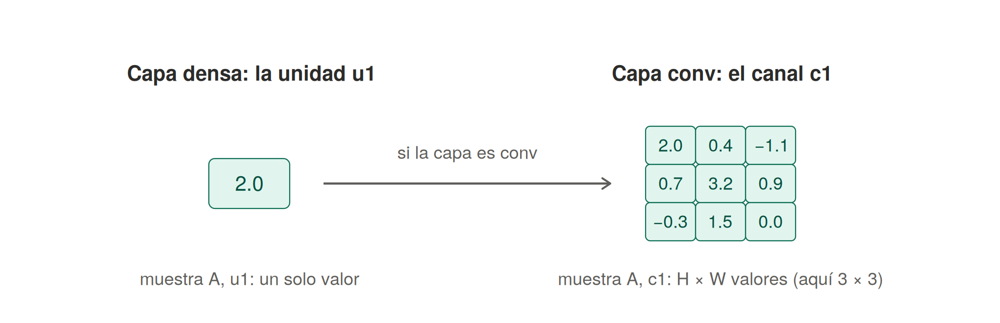

#### Batch versus Layer normalization

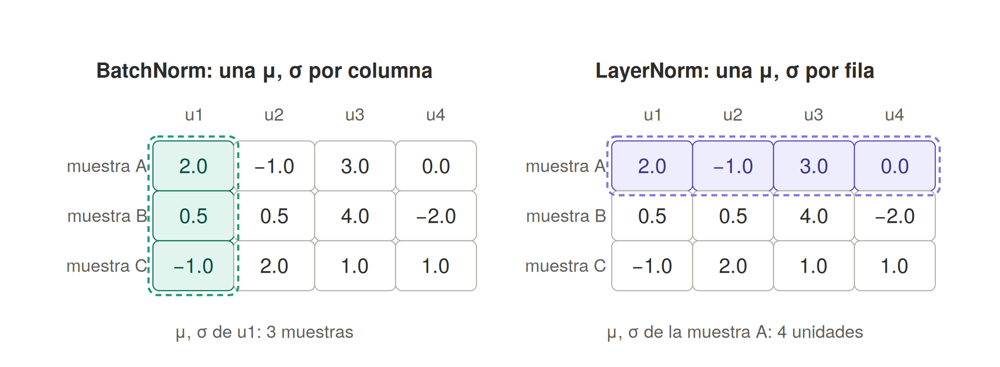

#### Lo mejor de ambos mundos: Group normalization

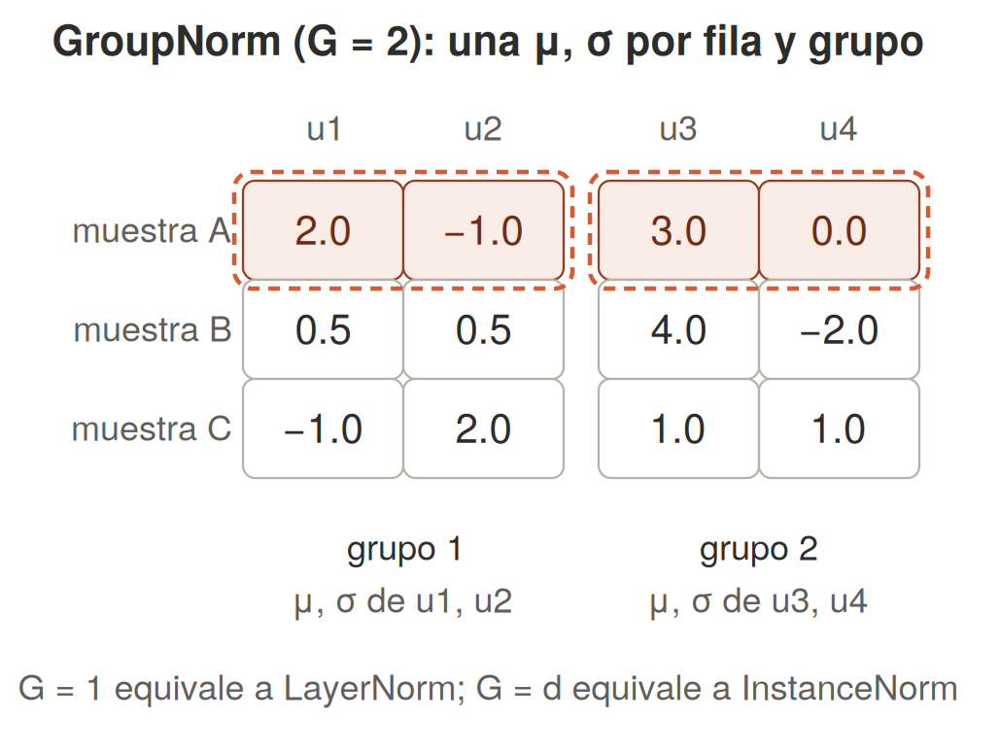

#### Comparando todos

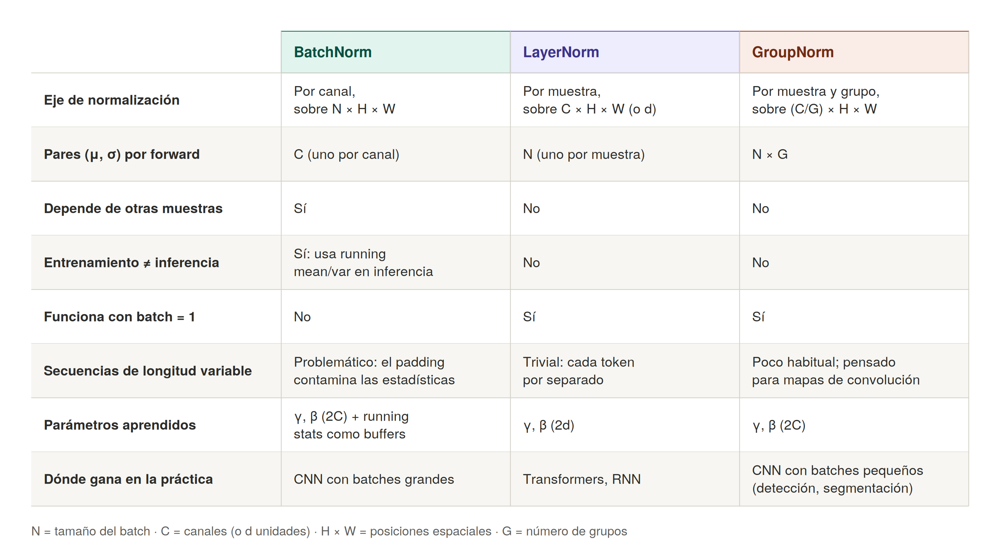

#### Regresamos a imagen del paper

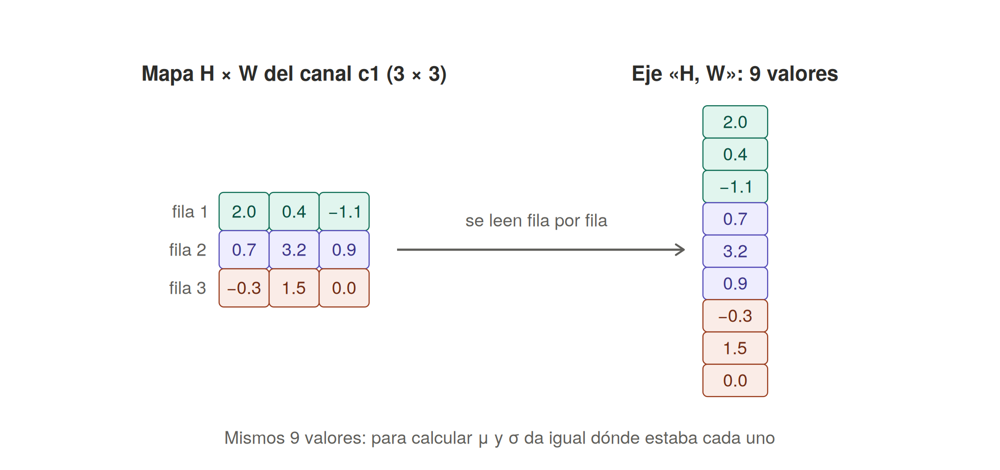

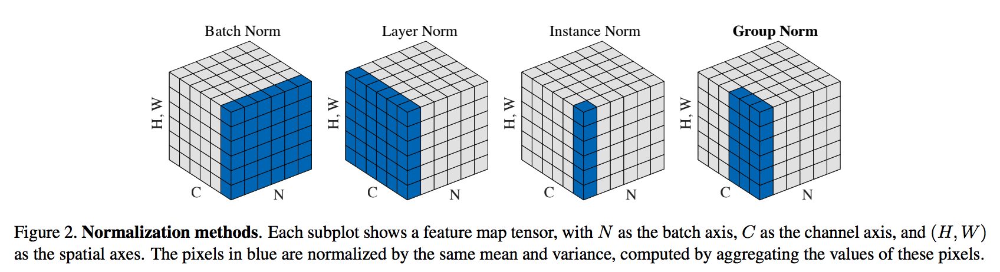

> Santurkar et al. (2018, How Does Batch Normalization Help Optimization? [paper](https://arxiv.org/abs/1805.11604)

## 2.13 Dropout

Durante el entrenamiento, cada neurona se apaga con probabilidad $p$ (y las restantes se re-escalan por $1/(1-p)$); en inferencia se usan todas. Obliga a la red a no depender de neuronas concretas y reduce el sobreajuste.

En las CNN se aplica sobre todo en las capas lineales del final, que son las que concentran los parámetros (fue justamente para eso que lo introdujo AlexNet). En las capas convolucionales es menos efectivo porque los píxeles vecinos están correlacionados; allí se prefieren variantes como `SpatialDropout2D` / `Dropout2d`, que apagan canales completos.

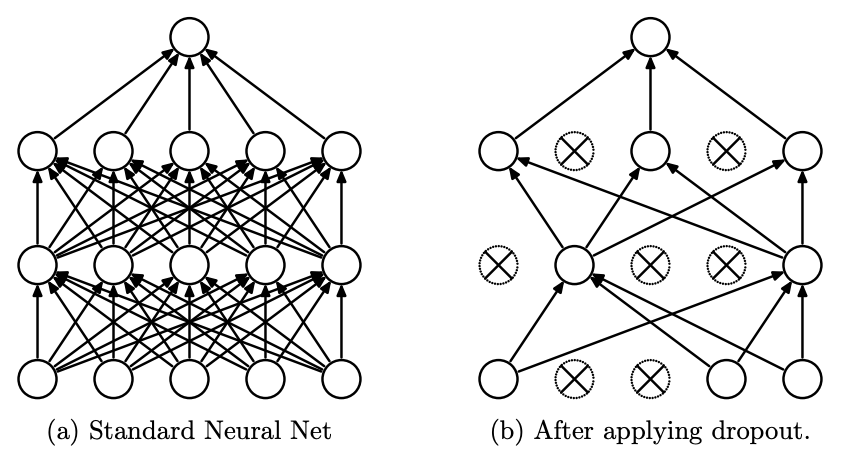

## 2.14 Técnicas de entrenamiento

Al igual que con redes neuronales convencionales podemos usar:

1. Técnicas basadas en gradiente
1. Stochastic GD
1. batch, or mini-batch GD
1. Adam
1. AdamW

# 3 Aplicaciones

## 3.1 Clasificación de imágenes

### 3.1.1 ImageNet

Hasta 2011 los clasificadores lograban colocar la clase real en el top 5 un 75% de las veces. 25% de las veces no formaba parte del top 5.

Solo 5 años después, las redes neuronales le ganaban a los seres humanos!

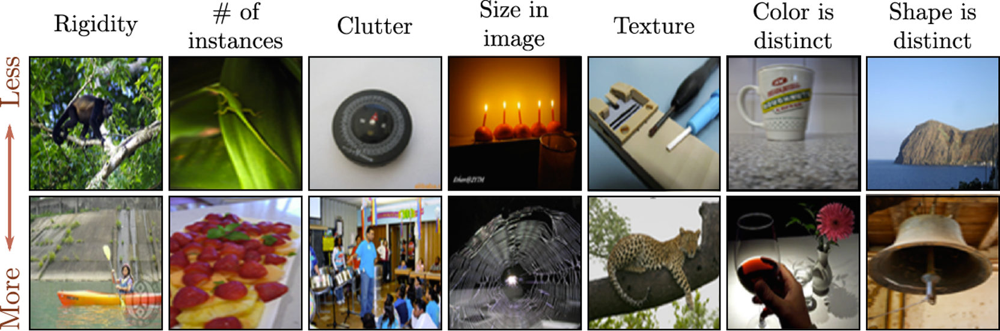

1. Imágenes 224x224
1. 1281167 imágenes de entrenamiento, 50.000 de validación y 100.000 imágenes de prueba
1. **1000 clases**

### 3.1.2 AlexNet

ImageNet classification with deep convolutional neural networks

1. Alex Krizhevsky (Verdadero creador)
1. Ilya Sutskever (Co-fundador y líder de investigación OpenAI)
1. Geoffrey Hinton (Premio Nobel)

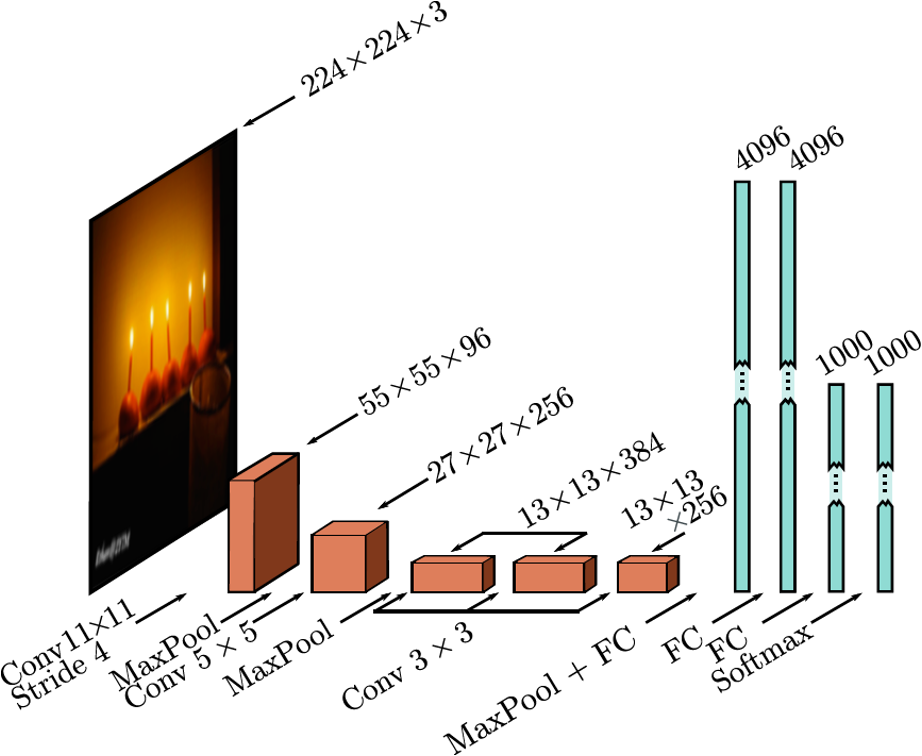

"We trained a large, deep convolutional neural network to classify the 1.2 million high-resolution images in the ImageNet LSVRC-2010 contest into the 1000 different classes. On the test data, we achieved top-1 and top-5 error rates of 37.5% and 17.0% which is considerably better than the previous state-of-the-art. The neural network, which has 60 million parameters and 650,000 neurons, consists of five convolutional layers, some of which are followed by max-pooling layers, and three fully-connected layers with a final 1000-way softmax. To make training faster, we used non-saturating neurons and a very efficient GPU implementation of the convolution operation. To reduce overfitting in the fully-connected layers we employed a recently-developed regularization method called "dropout" that proved to be very effective. We also entered a variant of this model in the ILSVRC-2012 competition and achieved a winning top-5 test error rate of 15.3%, compared to 26.2% achieved by the second-best entry."

#### Aumentando el dataset

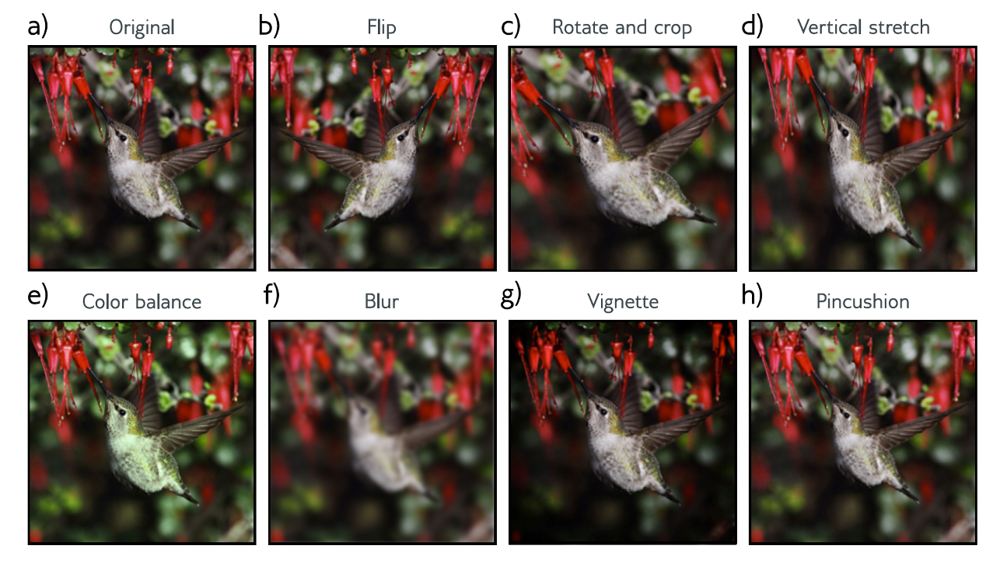

1. Factor de incremento de 2048
1. Transformaciones de localidad
1. Transformaciones de intensidad de píxeles

#### Regularizando las capas lineales

Inventaron Dropout para regularizar las capas lineales.

#### Detalles importantes

- En fase de prueba, promediaron los resultados de cinco versiones de las imágenes
- SGD con coeficiente de momentum 0.9 y batch size de 128.
- Regularizador L2 .
- Error de 16.4% top-5 y de 38.1% top-1.


### 3.1.3 Self-driving cars: [selfdrivingcars.mit.edu](https://selfdrivingcars.mit.edu)

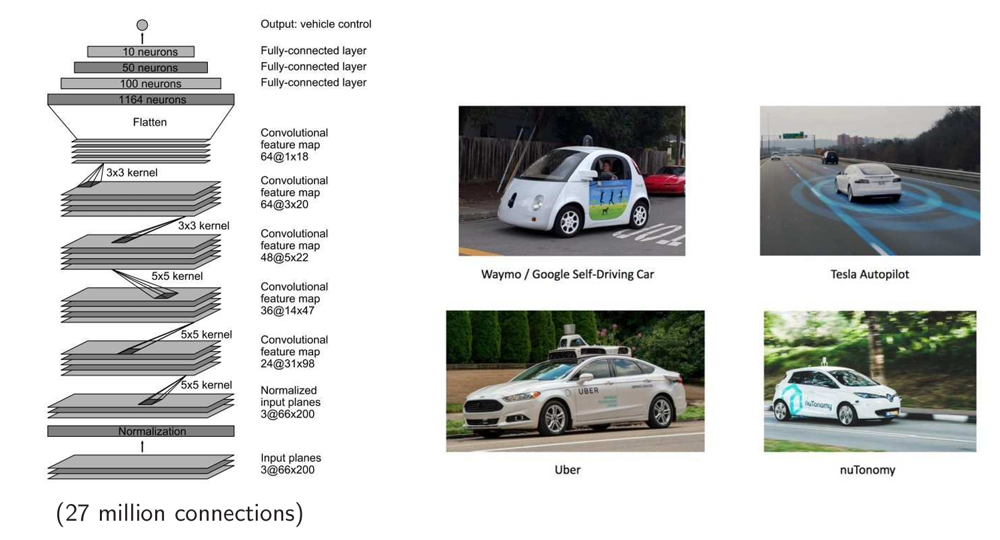

## 3.2 Segmentación de imágenes



### 3.2.1 U-Net: Convolutional Networks for Biomedical Image Segmentation

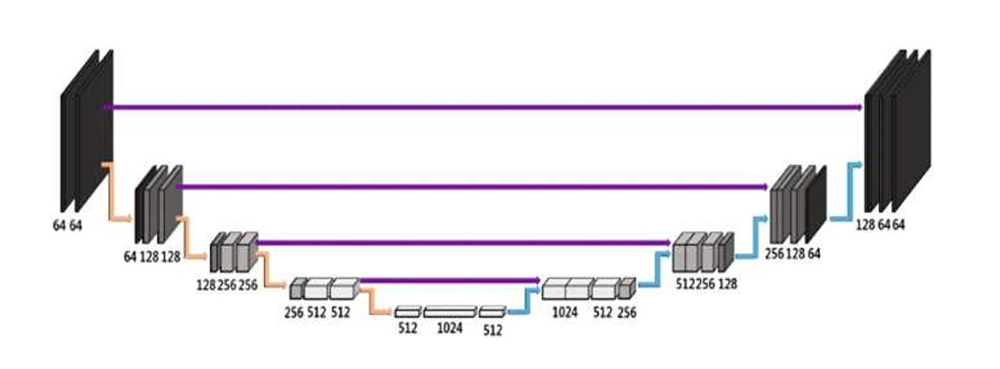

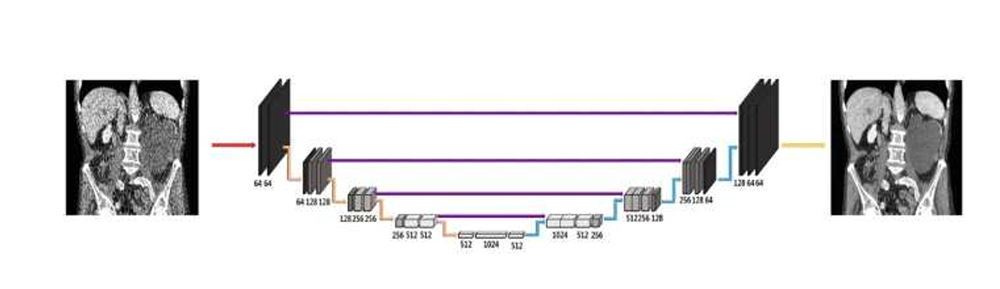

### 3.2.2 UZ Leuven segmentación de imágenes

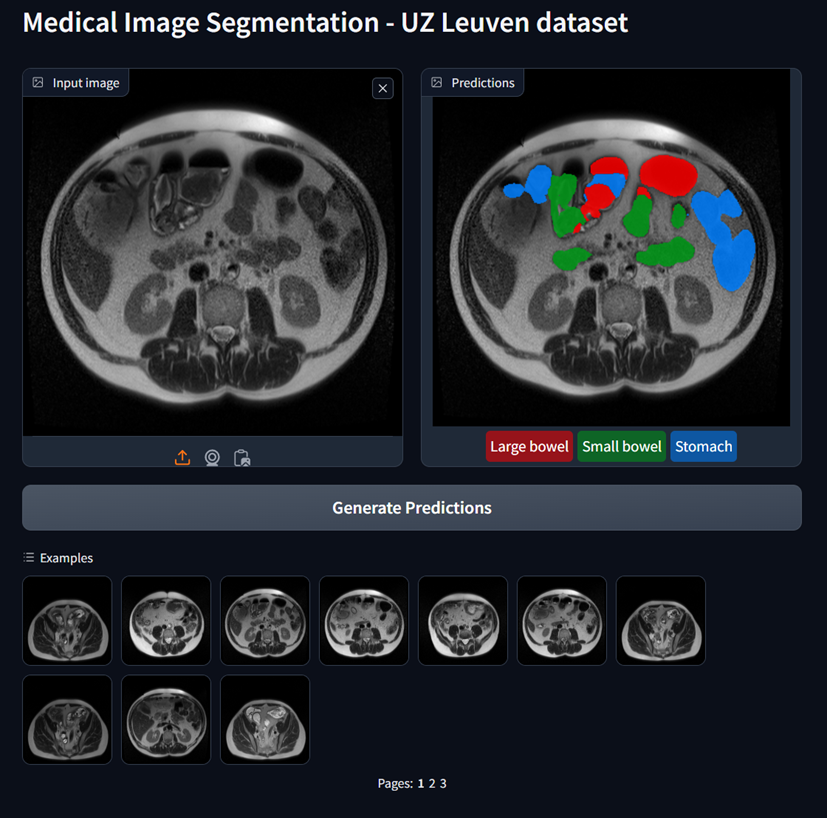

### 3.2.3 Semantic segmentation [UDL]

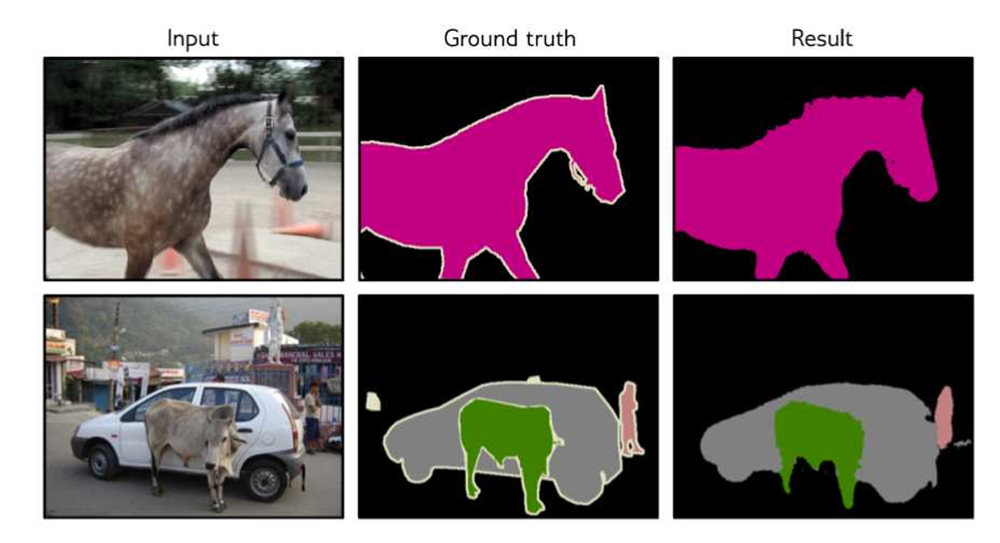

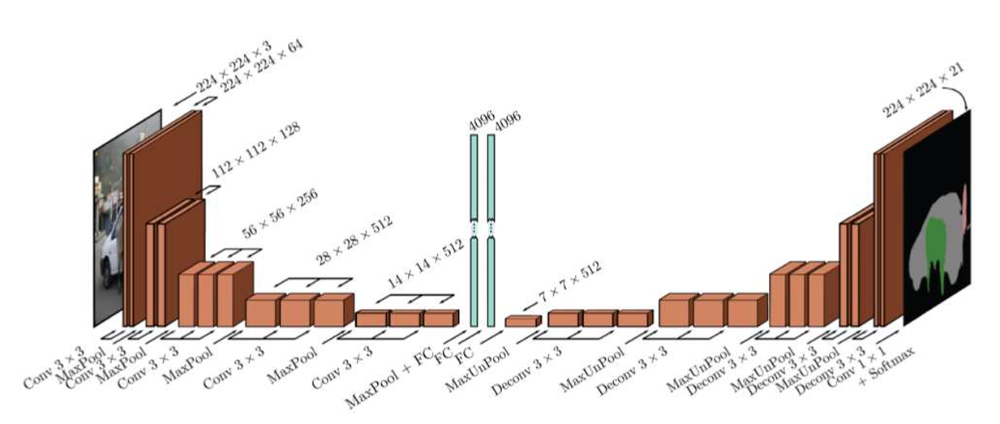

### 3.2.4 Object detection

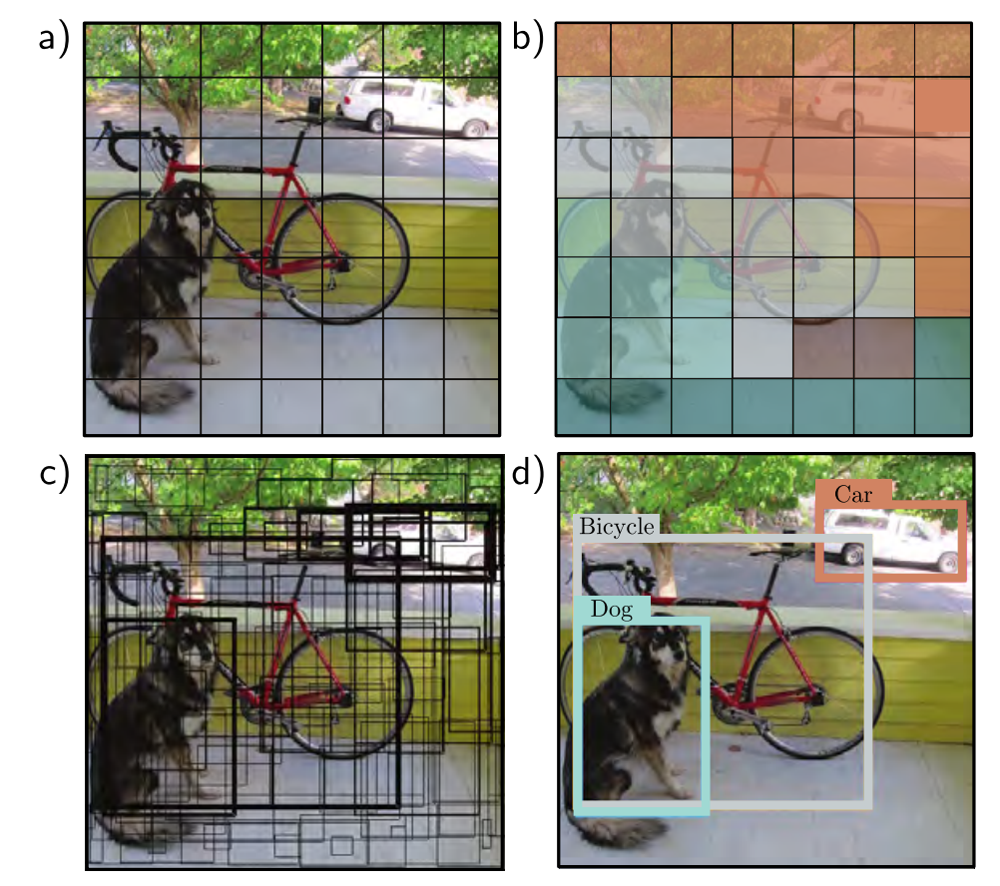

# 4 Keras: Ejemplo de clasificación Sign MNIST con Keras: FNN vs. CNN

Entrenaremos sobre el mismo dataset un modelo completamente conectado (FNN/MLP) y una CNN con el **mismo optimizador, mismos hiperparámetros y misma función de activación**, para comparar número de parámetros, velocidad de convergencia y precisión.

El [alfabeto del lenguaje de señas americano](http://www.asl.gs/) contiene 26 letras. Dos de esas letras (j y z) requieren movimiento, por lo que no están incluidas en el conjunto de datos de entrenamiento.

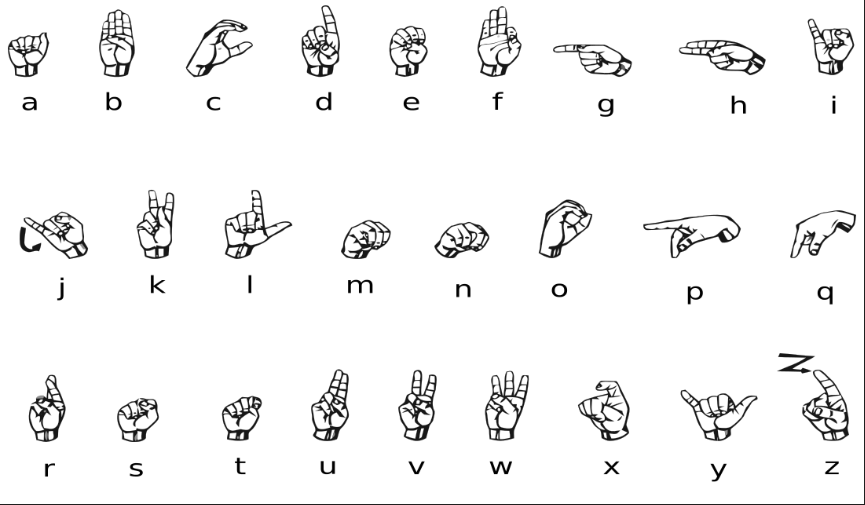

In [ ]:
import keras
from keras import layers
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Usar GPU

In [ ]:
import tensorflow as tf

In [ ]:
print("GPU: ", tf.config.list_physical_devices('GPU'))
if tf.config.list_physical_devices('GPU'):
    print("Usando GPU")
else:
    print("Usando CPU")

GPU:  [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Usando GPU


## Leyendo el dataset

In [ ]:
train_df = pd.read_csv("sign_mnist_train.csv")
valid_df = pd.read_csv("sign_mnist_test.csv")

train_df["label"] = train_df["label"].apply(lambda x: x - 1 if x >= 9 else x)
valid_df["label"] = valid_df["label"].apply(lambda x: x - 1 if x >= 9 else x)

y_train = train_df.pop('label')
y_valid = valid_df.pop('label')

x_train = train_df.values
x_valid = valid_df.values

In [ ]:
y_train

,label
0,3
1,6
2,2
3,2
4,12
...,...
27450,12
27451,22
27452,17
27453,16


## Visualizando el dataset

In [ ]:
import string

def create_signmnist_mapping():
    """Create bidirectional mapping for Sign MNIST"""

    # Get all uppercase letters except J and Z
    excluded_letters = {'J', 'Z'}
    letters = [letter for letter in string.ascii_uppercase if letter not in excluded_letters]

    # Label to class mapping
    label_to_class = dict(enumerate(letters))

    # Class to label mapping (reverse)
    class_to_label = {letter: label for label, letter in label_to_class.items()}

    return label_to_class, class_to_label

label_to_class, class_to_label = create_signmnist_mapping()

In [ ]:
label_to_class

{0: 'A',
 1: 'B',
 2: 'C',
 3: 'D',
 4: 'E',
 5: 'F',
 6: 'G',
 7: 'H',
 8: 'I',
 9: 'K',
 10: 'L',
 11: 'M',
 12: 'N',
 13: 'O',
 14: 'P',
 15: 'Q',
 16: 'R',
 17: 'S',
 18: 'T',
 19: 'U',
 20: 'V',
 21: 'W',
 22: 'X',
 23: 'Y'}

In [ ]:
def plot_sign_mnist(interest="all"):
    plt.figure(figsize=(40, 40))

    match interest:
        case "all":
            num_images, total = 20, 0
            for i in range(num_images):
                row = x_train[i ]
                label = y_train[i]

                image = row.reshape(28, 28)
                plt.subplot(1, num_images, i + 1)
                plt.title(label_to_class[label], fontdict={'fontsize': 30})
                plt.axis('off')
                plt.imshow(image, cmap='gray')
        case _:
            if interest in class_to_label.keys():
                num_images, total, i = 20, 0, 0
                while total < num_images:
                    row = x_train[i]
                    label = y_train[i]

                    if interest in label_to_class[label]:
                        image = row.reshape(28, 28)
                        plt.subplot(1, num_images, total + 1)
                        plt.title(label_to_class[label], fontdict={'fontsize': 30})
                        plt.axis('off')
                        plt.imshow(image, cmap='gray')
                        total += 1

                    i += 1
            else:
                raise ValueError("Wrong interest letter!")

    plt.tight_layout()
    plt.show()


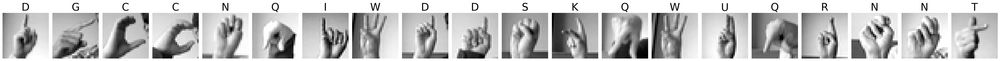

In [ ]:
plot_sign_mnist()

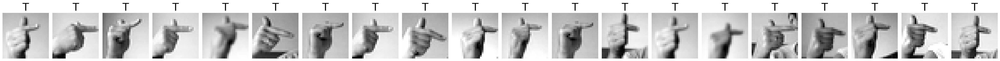

In [ ]:
plot_sign_mnist("T")

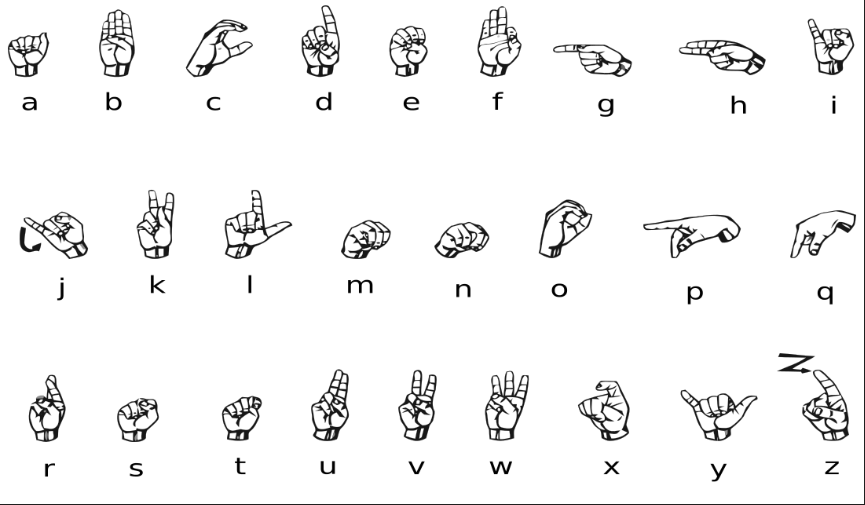

## Entrenamiento

### Objetivo

In [ ]:
n_classes = 24

### Hiperparámetros


In [ ]:
weight_decay = 0.0001
batch_size = 128
num_epochs = 20        # Recomendado: 50
learning_rate = 0.001
input_size = 28 * 28
image_size = 28

### Modelo lineal (FNN)

- Los píxeles los tenemos en el rango [0–255].
- Todos los modelos empiezan con `Rescaling(1./255)` para llevarlos a $[0, 1]$: sin esto, las ReLU se saturan con `learning_rate` alto y la red se queda en ~4% de accuracy.

**Por qué creen que sucede esto?**


#### Opción 1: Rescale

In [ ]:
def build_mlp(name="mlp"):
    return keras.Sequential([
        layers.Input(shape=(input_size,)),
        layers.Rescaling(1./255),
        layers.Dense(512, activation='relu', kernel_initializer='he_normal'),
        layers.Dropout(0.1),
        layers.Dense(512, activation='relu', kernel_initializer='he_normal'),
        layers.Dropout(0.1),
        layers.Dense(n_classes)
    ], name=name)

#### Opción 2: Normalizando

- La alternativa es `layers.Normalization()`, pero **hay que llamar a `.adapt(x_train)`** antes de entrenar: sin `adapt`, esa capa es la identidad.

In [ ]:
norm = layers.Normalization()
# calcula media y varianza por píxel sobre TODO x_train
norm.adapt(x_train)
model = keras.Sequential([layers.Input(shape=(784,)), norm, ...])

#### Creamos nuestra red lineal

In [ ]:
mlp = build_mlp()
mlp.summary()

Model: "mlp"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │       401,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 24)             │        12,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 676,888 (2.58 MB)

 Trainable params: 676,888 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

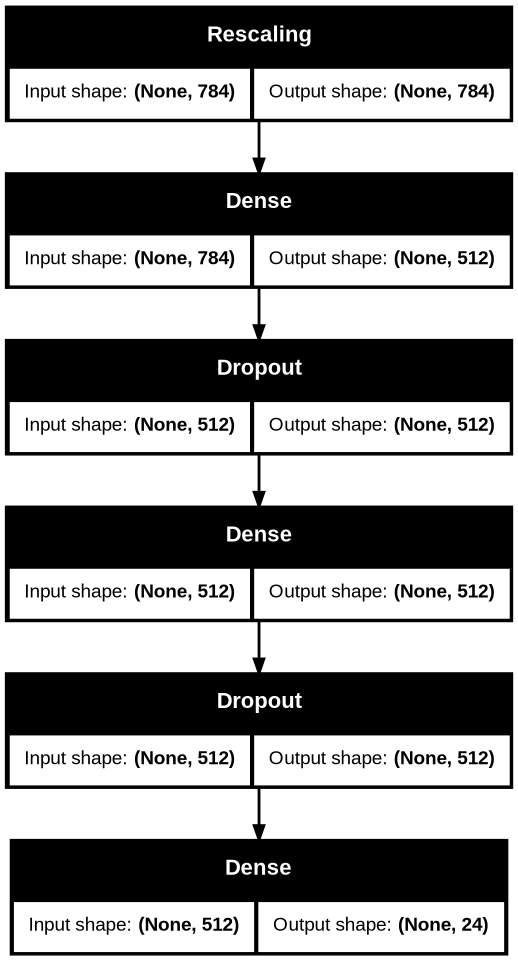

In [ ]:
keras.utils.plot_model(mlp, "MLP_simple.png", dpi=100, show_shapes=True)

### CNN

Misma cabeza lineal, pero la extracción de características se hace con tres bloques Conv → MaxPool. Las convoluciones usan `stride=1` y `padding='same'` (conservan el tamaño) y es el pooling quien reduce a la mitad: $28 \to 14 \to 7 \to 3$.

Verifica la columna *Output Shape* y la de *Param #* del `summary()` con las fórmulas de la sección 2.2.

In [ ]:
def build_cnn(name="cnn"):
    return keras.Sequential([
        layers.Input(shape=(input_size,)),                                  # (784,)
        layers.Rescaling(1./255),
        layers.Reshape((image_size, image_size, 1)),                        # 28 x 28 x 1
        layers.Conv2D(32, kernel_size=3, padding='same', activation='relu'),   # 28 x 28 x 32
        layers.MaxPool2D(pool_size=2),                                          # 14 x 14 x 32
        layers.Conv2D(64, kernel_size=3, padding='same', activation='relu'),   # 14 x 14 x 64
        layers.MaxPool2D(pool_size=2),                                          #  7 x  7 x 64
        layers.Conv2D(128, kernel_size=3, padding='same', activation='relu'),  #  7 x  7 x 128
        layers.MaxPool2D(pool_size=2),                                          #  3 x  3 x 128
        layers.Flatten(),                                                       # 1152
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.2),
        layers.Dense(n_classes)
    ], name=name)

cnn = build_cnn()
cnn.summary()

Model: "cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 7, 7, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 3, 3, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 24)             │         3,096 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 243,352 (950.59 KB)

 Trainable params: 243,352 (950.59 KB)

 Non-trainable params: 0 (0.00 B)

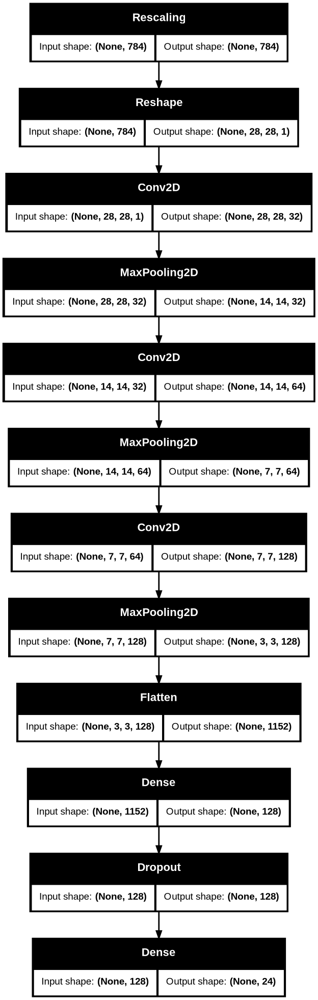

In [ ]:
keras.utils.plot_model(cnn, "cnn_simple.png", dpi=100, show_shapes=True)

### Mini ResNet (opcional) `proximamente`

Una tercera variante con una conexión residual (`x + residual`) y `GlobalAveragePooling2D` en lugar de `Flatten`. Compara su número de parámetros con los dos anteriores.

In [ ]:
def build_mini_resnet(name="mini_resnet"):
    inputs = keras.Input(shape=(input_size,))
    x = layers.Rescaling(1./255)(inputs)
    x = layers.Reshape((image_size, image_size, 1))(x)
    x = layers.Conv2D(32, 3, activation="relu")(x)
    x = layers.Conv2D(64, 3, activation="relu")(x)
    residual = x = layers.MaxPooling2D(3)(x)

    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = layers.Conv2D(64, 3, activation="relu", padding="same")(x)
    x = x + residual

    x = layers.Conv2D(64, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(256, activation="relu")(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(n_classes)(x)
    return keras.Model(inputs, outputs, name=name)

mini_resnet = build_mini_resnet()
mini_resnet.summary()

In [ ]:
keras.utils.plot_model(mini_resnet, "resnet.png", dpi=100, show_shapes=True)

### Entrenamiento

`run_experiment` compila, entrena y evalúa un modelo, y devuelve un diccionario con el historial y las métricas para poder comparar varios modelos después. Acepta datos alternativos (lo usaremos en el experimento de píxeles permutados).

In [ ]:
def run_experiment(model, x_tr=None, y_tr=None, x_te=None, y_te=None, verbose=1):
    # Por defecto usa los datos globales
    x_tr = x_train if x_tr is None else x_tr
    y_tr = y_train if y_tr is None else y_tr
    x_te = x_valid if x_te is None else x_te
    y_te = y_valid if y_te is None else y_te

    # Por defecto vamos a usar parámetros globales pero se podrían pasar por parámetro de ser necesario

    optimizer = keras.optimizers.AdamW(
        learning_rate=learning_rate,
        weight_decay=weight_decay,
        clipnorm=1.0  # Evita explosión del gradiente
    )
    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=[
            keras.metrics.SparseCategoricalAccuracy(name="acc"),
            keras.metrics.SparseTopKCategoricalAccuracy(5, name="top5-acc"),
        ],
    )

    callbacks = [
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=verbose),
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True, verbose=verbose),
        keras.callbacks.TerminateOnNaN(),
    ]

    history = model.fit(
        x=x_tr, y=y_tr,
        batch_size=batch_size,
        epochs=num_epochs,
        validation_split=0.1,
        callbacks=callbacks,
        verbose=verbose,
    )

    test_loss, test_acc, test_top5 = model.evaluate(x_te, y_te, verbose=0)
    print(f"[{model.name}] Test accuracy: {test_acc*100:.2f}% | top-5: {test_top5*100:.2f}% "
          f"| parámetros: {model.count_params():,} | épocas: {len(history.history['loss'])}")

    return {"name": model.name, "model": model, "history": history,
            "test_acc": test_acc, "test_top5": test_top5,
            "params": model.count_params(), "epochs": len(history.history["loss"])}

In [ ]:
results = {}
results["mlp"] = run_experiment(build_mlp())

Epoch 1/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 8s 19ms/step - acc: 0.4237 - loss: 1.9120 - top5-acc: 0.7792 - val_acc: 0.6595 - val_loss: 1.0733 - val_top5-acc: 0.9618 - learning_rate: 0.0010
Epoch 2/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.7085 - loss: 0.9255 - top5-acc: 0.9613 - val_acc: 0.6497 - val_loss: 0.9539 - val_top5-acc: 0.9763 - learning_rate: 0.0010
Epoch 3/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.8046 - loss: 0.6056 - top5-acc: 0.9858 - val_acc: 0.8878 - val_loss: 0.3980 - val_top5-acc: 0.9978 - learning_rate: 0.0010
Epoch 4/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - acc: 0.8789 - loss: 0.3753 - top5-acc: 0.9964 - val_acc: 0.8365 - val_loss: 0.4205 - val_top5-acc: 0.9996 - learning_rate: 0.0010
Epoch 5/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.9153 - loss: 0.2688 - top5-acc: 0.9990 - val_acc: 0.9527 - val_loss: 0.1667 - val_top5-acc: 0.9996 - learning_rate: 0.0010
Epoch 6/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - acc: 0.9412 - loss: 0.193

In [ ]:
results["cnn"] = run_experiment(build_cnn())

Epoch 1/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - acc: 0.4197 - loss: 1.8870 - top5-acc: 0.7277 - val_acc: 0.8227 - val_loss: 0.5453 - val_top5-acc: 0.9905 - learning_rate: 0.0010
Epoch 2/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.8637 - loss: 0.3986 - top5-acc: 0.9964 - val_acc: 0.9701 - val_loss: 0.1159 - val_top5-acc: 1.0000 - learning_rate: 0.0010
Epoch 3/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.9560 - loss: 0.1352 - top5-acc: 0.9999 - val_acc: 0.9967 - val_loss: 0.0290 - val_top5-acc: 1.0000 - learning_rate: 0.0010
Epoch 4/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - acc: 0.9828 - loss: 0.0583 - top5-acc: 1.0000 - val_acc: 0.9989 - val_loss: 0.0112 - val_top5-acc: 1.0000 - learning_rate: 0.0010
Epoch 5/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - acc: 0.9900 - loss: 0.0362 - top5-acc: 1.0000 - val_acc: 1.0000 - val_loss: 0.0024 - val_top5-acc: 1.0000 - learning_rate: 0.0010
Epoch 6/20
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - acc: 0.9923 - loss: 0.02

In [ ]:
# Opcional (tarda un poco más):
# results["mini_resnet"] = run_experiment(build_mini_resnet())

### Comparación FNN vs. CNN

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

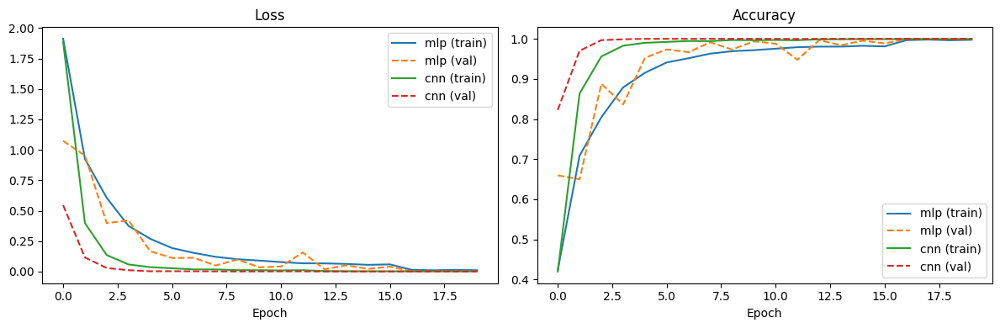

In [ ]:
def plot_comparison(results):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for r in results.values():
        h = r["history"].history
        # Deberíamos usar test
        ax[0].plot(h["loss"], label=f'{r["name"]} (train)')
        ax[0].plot(h["val_loss"], "--", label=f'{r["name"]} (val)')
        ax[1].plot(h["acc"], label=f'{r["name"]} (train)')
        ax[1].plot(h["val_acc"], "--", label=f'{r["name"]} (val)')
    ax[0].set_title("Loss");     ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    plt.tight_layout()
    plt.show()

plot_comparison(results)

In [ ]:
import pandas as pd

tabla = pd.DataFrame([{
    "Modelo": r["name"],
    "Parámetros": r["params"],
    "Épocas": r["epochs"],
    "Val acc (mejor)": max(r["history"].history["val_acc"]),
    "Test acc": r["test_acc"],
    "Test top-5": r["test_top5"],
} for r in results.values()])

tabla.round(4)

,Modelo,Parámetros,Épocas,Val acc (mejor),Test acc,Test top-5
0,mlp,676888,20,1.0,0.8370,0.9773
1,cnn,243352,20,1.0,0.9522,0.9976


**Qué observar:**

1. La CNN tiene menos parámetros que la FNN (~243k vs. ~677k) y aun así alcanza mayor precisión en test.
1. La FNN llega a ~100% en entrenamiento pero se estanca en validación/test: memoriza. Es el problema de "muchos parámetros, pocos datos" de la sección 2.1. En Sign MNIST el efecto se amplifica porque el conjunto de test contiene manos y fondos distintos a los de entrenamiento.
1. Fíjate dónde están los parámetros de la CNN: la mayoría en la capa `Dense(128)` después del `Flatten`, no en las convoluciones. Compara con el `mini_resnet`, que usa GAP.

In [ ]:
def plot_detailed_confusion_matrix(model, x_test, y_test, class_names):
    # Predictions
    y_pred = model.predict(x_test)
    y_pred_classes = np.argmax(y_pred, axis=1)

    # True classes
    if len(y_test.shape) > 1:
        y_true = np.argmax(y_test, axis=1)
    else:
        y_true = y_test

    # Confusion matrix
    cm = confusion_matrix(y_true, y_pred_classes)

    # Calculate percentages
    cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

    # Create subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

    # Raw counts
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax1,
                xticklabels=class_names, yticklabels=class_names)
    ax1.set_title('Confusion Matrix (Counts)')
    ax1.set_xlabel('Predicted')
    ax1.set_ylabel('Actual')

    # Percentages
    sns.heatmap(cm_percent, annot=True, fmt='.1f', cmap='Blues', ax=ax2,
                xticklabels=class_names, yticklabels=class_names)
    ax2.set_title('Confusion Matrix (Percentages)')
    ax2.set_xlabel('Predicted')
    ax2.set_ylabel('Actual')

    plt.tight_layout()
    plt.show()

    # Print classification report
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred_classes, target_names=class_names))

    return cm, cm_percent



225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


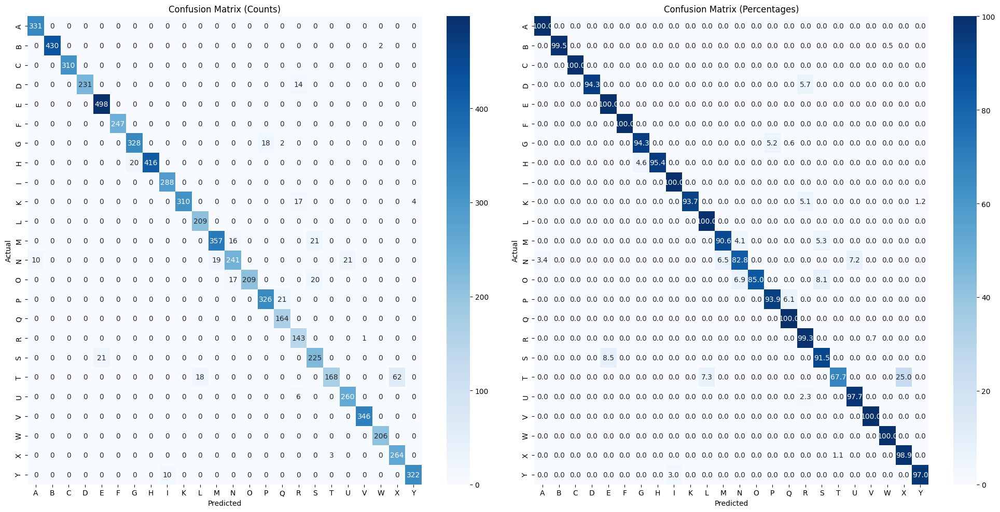


Classification Report:
              precision    recall  f1-score   support

           A       0.97      1.00      0.99       331
           B       1.00      1.00      1.00       432
           C       1.00      1.00      1.00       310
           D       1.00      0.94      0.97       245
           E       0.96      1.00      0.98       498
           F       1.00      1.00      1.00       247
           G       0.94      0.94      0.94       348
           H       1.00      0.95      0.98       436
           I       0.97      1.00      0.98       288
           K       1.00      0.94      0.97       331
           L       0.92      1.00      0.96       209
           M       0.95      0.91      0.93       394
           N       0.88      0.83      0.85       291
           O       1.00      0.85      0.92       246
           P       0.95      0.94      0.94       347
           Q       0.88      1.00      0.93       164
           R       0.79      0.99      0.88       144
   

In [ ]:
# Matriz de confusión del mejor modelo (cambia la clave para ver otro)
class_names = list(label_to_class.values())
cm_counts, cm_percent = plot_detailed_confusion_matrix(results["cnn"]["model"], x_valid, y_valid, class_names)

#### Comparar resultados en errores

Qué les parece interesante comparar?

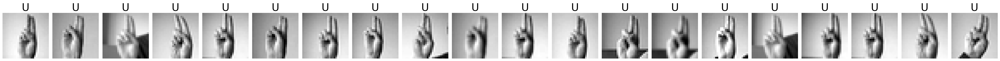

In [ ]:
plot_sign_mnist("U")

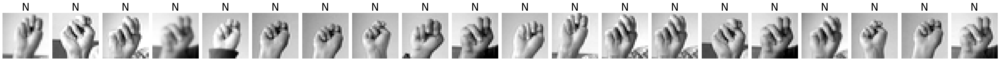

In [ ]:
plot_sign_mnist("N")

#### Evaluación final

In [ ]:
# Evaluación final de todos los modelos entrenados
for r in results.values():
    test_loss, top1acc, top5acc = r["model"].evaluate(x_valid, y_valid, verbose=0)
    print(f'{r["name"]:>12s} | loss: {test_loss:.4f} | top-1: {top1acc:.4f} | top-5: {top5acc:.4f}')

         mlp | loss: 0.7714 | top-1: 0.8370 | top-5: 0.9773
         cnn | loss: 0.2206 | top-1: 0.9522 | top-5: 0.9976


### Experimento opcional: ¿qué pasa si barajamos los píxeles?

Aplicamos la **misma permutación fija** a los píxeles de todas las imágenes (entrenamiento y test). La imagen deja de ser reconocible para un humano, pero la información es exactamente la misma.

- Para la FNN, permutar las entradas equivale a permutar las columnas de la matriz de pesos de la primera capa: **aprende igual**.
- Para la CNN, los vecindarios $3 \times 3$ ya no contienen píxeles vecinos: el sesgo inductivo de localidad deja de ser válido y la precisión cae.

Es la demostración empírica de la sección 2.1.b.

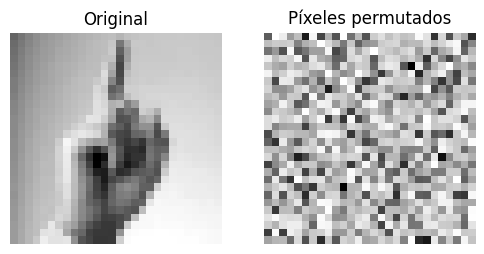

[mlp_perm] Test accuracy: 83.48% | top-5: 97.02% | parámetros: 676,888 | épocas: 20
[cnn_perm] Test accuracy: 78.23% | top-5: 95.89% | parámetros: 243,352 | épocas: 20


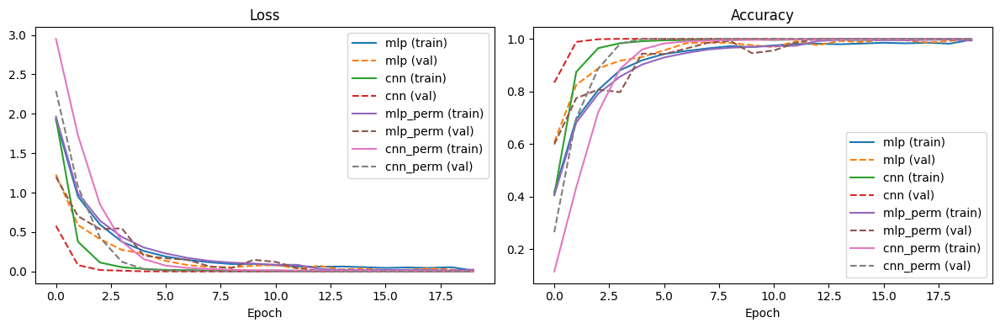

In [ ]:
rng = np.random.default_rng(42)
perm = rng.permutation(input_size)
x_train_perm, x_valid_perm = x_train[:, perm], x_valid[:, perm]

plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1); plt.imshow(x_train[0].reshape(28, 28), cmap='gray');      plt.title("Original");          plt.axis('off')
plt.subplot(1, 2, 2); plt.imshow(x_train_perm[0].reshape(28, 28), cmap='gray'); plt.title("Píxeles permutados"); plt.axis('off')
plt.show()

results_perm = {}
results_perm["mlp_perm"] = run_experiment(build_mlp("mlp_perm"), x_train_perm, y_train, x_valid_perm, y_valid, verbose=0)
results_perm["cnn_perm"] = run_experiment(build_cnn("cnn_perm"), x_train_perm, y_train, x_valid_perm, y_valid, verbose=0)

plot_comparison({**results, **results_perm})

# 5 PyTorch: Ejemplo clasificación Sign Mnist con PyTorch

In [ ]:
import os
os.environ['CUDA_LAUNCH_BLOCKING'] = "1"
os.environ['TORCH_USE_CUDA_DSA'] = '1'

In [ ]:
import torch.nn as nn
import pandas as pd
import torch
from torch.optim import Adam
from torch.utils.data import Dataset, DataLoader
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


El [alfabeto del lenguaje de señas americano](http://www.asl.gs/) contiene 26 letras. Dos de esas letras (j y z) requieren movimiento, por lo que no están incluidas en el conjunto de datos de entrenamiento.

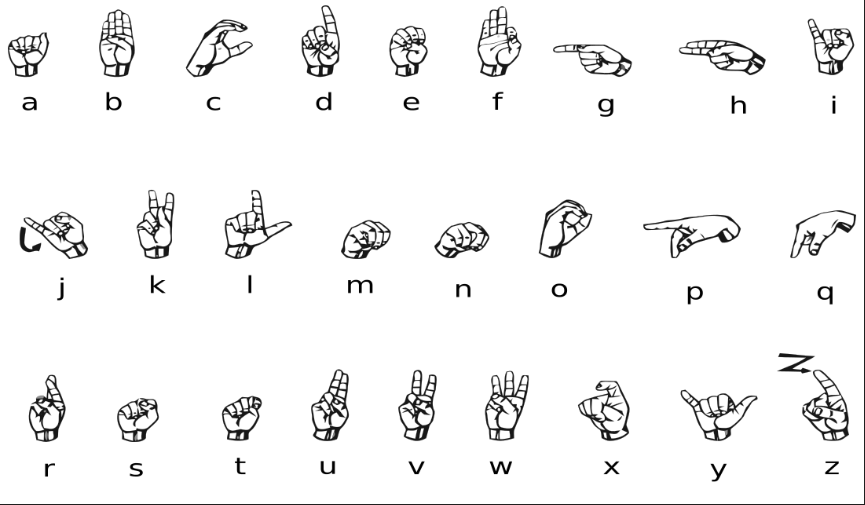

## Preprocesamiento de datos

In [ ]:
train_df = pd.read_csv("sign_mnist_train.csv")
valid_df = pd.read_csv("sign_mnist_test.csv")

In [ ]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,3,107,118,127,134,139,143,146,150,153,...,207,207,207,207,206,206,206,204,203,202
1,6,155,157,156,156,156,157,156,158,158,...,69,149,128,87,94,163,175,103,135,149
2,2,187,188,188,187,187,186,187,188,187,...,202,201,200,199,198,199,198,195,194,195
3,2,211,211,212,212,211,210,211,210,210,...,235,234,233,231,230,226,225,222,229,163
4,13,164,167,170,172,176,179,180,184,185,...,92,105,105,108,133,163,157,163,164,179


In [ ]:
np.sqrt(train_df.shape[1]-1)

np.float64(28.0)

In [ ]:
train_df.shape

(27455, 785)

In [ ]:
y_train = train_df.pop('label')
y_valid = valid_df.pop('label')

# Las etiquetas van de 0 a 24 saltando el 9 (la J no está en el dataset).
# Las remapeamos a 0..23 para que coincidan con n_classes = 24.
y_train = y_train.apply(lambda x: x - 1 if x > 9 else x)
y_valid = y_valid.apply(lambda x: x - 1 if x > 9 else x)
y_train

### Extraer imágenes

In [ ]:
x_train = train_df.values
x_valid = valid_df.values
x_train

array([[107, 118, 127, ..., 204, 203, 202],
       [155, 157, 156, ..., 103, 135, 149],
       [187, 188, 188, ..., 195, 194, 195],
       ...,
       [174, 174, 174, ..., 202, 200, 200],
       [177, 181, 184, ...,  64,  87,  93],
       [179, 180, 180, ..., 205, 209, 215]])

In [ ]:
x_train.shape

(27455, 784)

### Visualizar imágenes

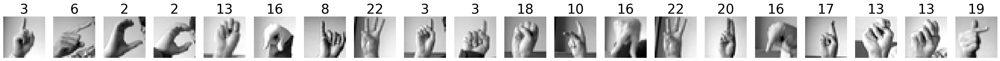

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(40,40))

num_images = 20
for i in range(num_images):
    row = x_train[i]
    label = y_train[i]

    image = row.reshape(28,28)
    plt.subplot(1, num_images, i+1)
    plt.title(label, fontdict={'fontsize': 30})
    plt.axis('off')
    plt.imshow(image, cmap='gray')

### Normalización

In [ ]:
x_train = train_df.values / 255
x_valid = valid_df.values / 255

## Creando datasets customizables

###  Definición del Dataset

In [ ]:
class SignMNIST(Dataset):
    def __init__(self, x_df, y_df, device="cuda"):
        self.device = torch.device("cuda" if torch.cuda.is_available() and device == "cuda" else "cpu")
        self.xs = torch.tensor(x_df).float().to(self.device)
        self.ys = torch.tensor(y_df).to(self.device)

    def __getitem__(self, idx):
        x = self.xs[idx]
        y = self.ys[idx]
        return x, y

    def __len__(self):
        return len(self.xs)

In [ ]:
# Check the raw data before creating the dataset
print("=== Raw Data Check ===")
print(f"x_train shape: {x_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_train dtype: {x_train.dtype}")
print(f"y_train dtype: {y_train.dtype}")

# Critical: Check label range
print(f"y_train min: {y_train.min()}")
print(f"y_train max: {y_train.max()}")
print(f"Unique labels: {np.unique(y_train)}")

# Check for problematic values
print(f"Any NaN in x_train: {np.isnan(x_train).any()}")
print(f"Any inf in x_train: {np.isinf(x_train).any()}")

La idea fundamental en PyTorch es separar el diseño de la **Estructura** de los datos de la **lógica** para usarlos. La **lógica** la vamos a modificar usando un [DataLoader](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html#preparing-your-data-for-training-with-dataloaders)

### El DataLoader

In [ ]:
BATCH_SIZE = 32

train_data = SignMNIST(x_train, y_train, device=device)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
train_N = len(train_loader.dataset)

In [ ]:
valid_data = SignMNIST(x_valid, y_valid, device=device)
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE)
valid_N = len(valid_loader.dataset)

In [ ]:
train_loader

In [ ]:
batch = next(iter(train_loader))
batch

[tensor([[0.6706, 0.6902, 0.7098,  ..., 0.0588, 0.0314, 0.0627],
         [0.5020, 0.5176, 0.5294,  ..., 0.7137, 0.7137, 0.7059],
         [0.6824, 0.6941, 0.7020,  ..., 0.7569, 0.7490, 0.7412],
         ...,
         [0.5020, 0.5176, 0.5333,  ..., 0.6706, 0.6627, 0.6588],
         [0.7412, 0.7490, 0.7569,  ..., 0.7882, 0.7765, 0.7725],
         [0.0431, 0.1961, 0.2784,  ..., 0.5373, 0.5725, 0.5176]]),
 tensor([ 6, 23, 24, 24, 23, 23, 10, 17, 20, 21,  8,  6, 20,  5, 23, 11, 18,  6,
         15, 11, 12, 18, 19, 16,  2, 20, 23, 24,  4, 19,  1,  1])]

### Dimensión del batch

In [ ]:
batch[0].shape

torch.Size([32, 784])

In [ ]:
batch[1].shape

torch.Size([32])

## Construyendo un modelo lineal

* Tiene una capa flatten.
* Tiene una capa de entrada densa. Esta capa debe contener 512 neuronas y utilizar la función de activación `relu`
* Tiene una segunda capa densa con 512 neuronas que utiliza la función de activación `relu`
* Tiene una capa de salida densa con neuronas igual al número de clases

In [ ]:
input_size = 28 * 28
n_classes = 24

In [ ]:
linear_model = nn.Sequential(
    nn.Flatten(), # Tiene la capa flatten
    nn.Linear(input_size, 512),  # La entrada es densa y contiene 512 neuronas
    nn.ReLU(),  # Usamos la función de activación ReLU
    nn.Linear(512, 512),  # Capa oculta
    nn.ReLU(),  # Activación para capa oculta
    nn.Linear(512, n_classes)
)

verifiquemos que el modelo es correcto y lo enviamos a la GPU

In [ ]:
device

device(type='cpu')

In [ ]:
linear_model = linear_model.to(device)

In [ ]:
linear_model = torch.compile(linear_model.to(device))
linear_model

OptimizedModule(
  (_orig_mod): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=512, bias=True)
    (2): ReLU()
    (3): Linear(in_features=512, out_features=512, bias=True)
    (4): ReLU()
    (5): Linear(in_features=512, out_features=25, bias=True)
  )
)

### Definiendo la función de pérdida

* Como estamos en el caso de clasificación usamos como `función de pérdida` la  ([Categorical CrossEntropy](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html))
* El algoritmo de optimización lo dejamos en el ADAM

In [ ]:
loss_function = nn.CrossEntropyLoss()
optimizer = Adam(linear_model.parameters())

## Entrenamiento

In [ ]:
def get_batch_accuracy(output, y, N, debug=False):
    if debug:
      print(y, N)
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct / N

In [ ]:
def train():
    loss = 0
    accuracy = 0

    linear_model.train()
    for x, y in train_loader:
        output = linear_model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()

        loss += batch_loss.item()
        accuracy += get_batch_accuracy(output, y, train_N)
    print('\nTrain - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

## Validación del modelo

In [ ]:
import numpy as np

def validate():
    loss = 0
    accuracy = 0

    linear_model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            output = linear_model(x)
            loss_value = loss_function(output, y).item()
            if np.isnan(loss_value):
              continue
            loss += loss_function(output, y).item()
            accuracy += get_batch_accuracy(output, y, valid_N)
    print('\nValid - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

## El ciclo simplicado de entrenamiento

In [ ]:
import torch._dynamo
torch._dynamo.config.suppress_errors = True

In [ ]:
epochs = 20

for epoch in range(epochs):
    print('\nEpoch: {}'.format(epoch))
    train()
    validate()

## Construyendo un modelo con CNN

In [ ]:
class SignCNNMNIST(Dataset):
    def __init__(self, x_df, y_df, IMG_CHS=1, IMG_WIDTH=28, IMG_HEIGHT=28, device="cuda"):
        self.device = torch.device("cuda" if torch.cuda.is_available() and device == "cuda" else "cpu")
        x_df = x_df.copy()
        x_df = x_df.values / 255
        x_df = x_df.reshape(-1, IMG_CHS, IMG_WIDTH, IMG_HEIGHT)
        self.xs = torch.tensor(x_df).float().to(self.device)
        self.ys = torch.tensor(y_df).to(device)

    def __getitem__(self, idx):
        x = self.xs[idx]
        y = self.ys[idx]
        return x, y

    def __len__(self):
        return len(self.xs)

In [ ]:
IMG_CHS=1
IMG_WIDTH=28
IMG_HEIGHT=28

In [ ]:
train_df = pd.read_csv("sign_mnist_train.csv")
valid_df = pd.read_csv("sign_mnist_test.csv")

In [ ]:
y_train = train_df.pop('label').apply(lambda x: x - 1 if x > 9 else x)
y_valid = valid_df.pop('label').apply(lambda x: x - 1 if x > 9 else x)

In [ ]:
BATCH_SIZE = 32

train_data = SignCNNMNIST(train_df, y_train, device=device)
train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
train_N = len(train_loader.dataset)

valid_data = SignCNNMNIST(valid_df, y_valid, device=device)
valid_loader = DataLoader(valid_data, batch_size=BATCH_SIZE)
valid_N = len(valid_loader.dataset)

In [ ]:
n_classes = 24
kernel_size = 3
flattened_img_size = 75 * 3 * 3

model = nn.Sequential(
    # First convolution
    nn.Conv2d(IMG_CHS, 25, kernel_size, stride=1, padding=1),  # 25 x 28 x 28
    nn.BatchNorm2d(25),
    nn.ReLU(),
    nn.MaxPool2d(2, stride=2),  # 25 x 14 x 14
    # Second convolution
    nn.Conv2d(25, 50, kernel_size, stride=1, padding=1),  # 50 x 14 x 14
    nn.BatchNorm2d(50),
    nn.ReLU(),
    nn.Dropout(.2),
    nn.MaxPool2d(2, stride=2),  # 50 x 7 x 7
    # Third convolution
    nn.Conv2d(50, 75, kernel_size, stride=1, padding=1),  # 75 x 7 x 7
    nn.BatchNorm2d(75),
    nn.ReLU(),
    nn.MaxPool2d(2, stride=2),  # 75 x 3 x 3
    # Flatten to Dense
    nn.Flatten(),
    nn.Linear(flattened_img_size, 512),
    nn.Dropout(.3),
    nn.ReLU(),
    nn.Linear(512, n_classes)
)

In [ ]:
model = torch.compile(model.to(device))
model

OptimizedModule(
  (_orig_mod): Sequential(
    (0): Conv2d(1, 25, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(25, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(25, 50, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(50, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.2, inplace=False)
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): Conv2d(50, 75, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (10): BatchNorm2d(75, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU()
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=675, out_features=512, bias=True)
    (15): Dropout

In [ ]:
loss_function = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters())

In [ ]:
def get_batch_accuracy(output, y, N):
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct / N

In [ ]:
def validate():
    loss = 0
    accuracy = 0

    model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            output = model(x)
            loss_value = loss_function(output, y).item()
            if np.isnan(loss_value):
              continue
            loss += loss_value
            accuracy += get_batch_accuracy(output, y, valid_N)
    print('\nValid - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

In [ ]:
def train():
    loss = 0
    accuracy = 0

    model.train()
    for x, y in train_loader:
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()

        loss += batch_loss.item()
        accuracy += get_batch_accuracy(output, y, train_N)
    print('\nTrain - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

In [ ]:
epochs = 20

for epoch in range(epochs):
    print('\nEpoch: {}'.format(epoch))
    train()
    validate()

# Modelo avanzado usando convolución

In [ ]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torchvision.datasets import MNIST
from torch.utils.data import DataLoader

class DoubleConv(nn.Module):
    """(convolution => [BN] => ReLU) * 2"""

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

class UNet(nn.Module):
    def __init__(self):
        super(UNet, self).__init__()
        self.down_conv1 = DoubleConv(1, 64)
        self.down_conv2 = DoubleConv(64, 128)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.upsample = nn.Upsample(scale_factor=2, mode='bilinear', align_corners=True)
        self.up_conv1 = DoubleConv(128, 64)

        self.avgpool = nn.AdaptiveAvgPool2d((1, 1)) # Add global average pooling layer
        self.fc = nn.Linear(64, 10) # Fully connected layer for classification

    def forward(self, x):
        # Encoder
        x1 = self.down_conv1(x)
        x2 = self.pool(x1)
        x3 = self.down_conv2(x2)
        # Decoder
        x = self.upsample(x3)
        x = self.up_conv1(x)
        # Global average pooling and fully connected layer
        x = self.avgpool(x)
        x = torch.flatten(x, 1) # Flatten the features
        x = self.fc(x) # Classification
        return x


In [ ]:
# Training settings (simplified for example)
model = UNet()
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# Load MNIST dataset
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = MNIST(root='./data', train=True, download=True, transform=transform)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

In [ ]:
# Simplified training loop
for epoch in range(1):
    for batch_idx, (data, target) in enumerate(train_loader):
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, target)
        loss.backward()
        optimizer.step()

        if batch_idx % 10 == 0:
            print(f'Epoch {epoch}, Batch {batch_idx}, Loss: {loss.item()}')


Epoch 0, Batch 0, Loss: 0.7603299021720886
Epoch 0, Batch 10, Loss: 0.6122781038284302
Epoch 0, Batch 20, Loss: 0.6150088906288147
Epoch 0, Batch 30, Loss: 0.5589423179626465
Epoch 0, Batch 40, Loss: 0.41421979665756226
Epoch 0, Batch 50, Loss: 0.36823949217796326
Epoch 0, Batch 60, Loss: 0.3452048599720001


KeyboardInterrupt: 

In [ ]:
import keras

from keras.models import Sequential
from keras.layers import Dense, Activation, LayerNormalization

model = Sequential([
    Dense(units=16, input_shape=(1,10), activation='relu'),
    LayerNormalization(axis=1),
    Dense(units=10, activation='relu'),
    LayerNormalization(axis=1),
    Dense(units=3, activation='softmax')
])


# Ejemplo de clasificación sin convolución

In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import Adam

# Visualization tools
import torchvision
import torchvision.transforms.v2 as transforms
import torchvision.transforms.functional as F
import matplotlib.pyplot as plt

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.cuda.is_available()

False

## El dataset MNIST

En la historia del aprendizaje automático usando redes neuronales, la clasificación de imágenes del [conjunto de datos MNIST](http://yann.lecun.com/exdb/mnist/), una colección de 70.000 imágenes en escala de grises de dígitos escritos a mano del 0 al 9, fue un desarrollo importante. Si bien hoy en día el problema se considera trivial, clasificar imágenes con MNIST se ha convertido en una especie de "Hola mundo" para el aprendizaje profundo.

En PyTorch, podemos usar nuestra GPU en nuestras operaciones configurando el [dispositivo](https://pytorch.org/docs/stable/tensor_attributes.html#torch.device) en `cuda`. La función `torch.cuda.is_available()` confirmará que PyTorch puede reconocer la GPU.

### Descargando los datos

In [ ]:
train_set = torchvision.datasets.MNIST("./data/", train=True, download=True)
valid_set = torchvision.datasets.MNIST("./data/", train=False, download=True)

## Explorando los datos

In [ ]:
x_0, y_0 = train_set[30]

In [ ]:
x_0

In [ ]:
type(x_0)

PIL.Image.Image

Qué número creen que es?

In [ ]:
y_0

3

## Transformando las imágenes

También podemos ver el tamaño de cada dimensión. PyTorch utiliza una convención `C x H x W`, lo que significa que la primera dimensión es el canal de color, la segunda es la altura y la tercera es el anch|o.

Como estas imágenes son en blanco y negro, solo hay 1 canal de color. Las imágenes son cuadradas y miden 28 píxeles de alto y ancho:

In [ ]:
trans = transforms.Compose([transforms.ToTensor()])
x_0_tensor = trans(x_0)

/usr/local/lib/python3.10/dist-packages/torchvision/transforms/v2/_deprecated.py:42: UserWarning: The transform `ToTensor()` is deprecated and will be removed in a future release. Instead, please use `v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)])`.Output is equivalent up to float precision.
  warnings.warn(


In [ ]:
type(x_0)

PIL.Image.Image

In [ ]:
x_0_tensor.shape

torch.Size([1, 28, 28])

In [ ]:
x_0_tensor.dtype

torch.float32

In [ ]:
x_0_tensor.min()

tensor(0.)

In [ ]:
x_0_tensor.max()

tensor(1.)

In [ ]:
x_0_tensor.size()

torch.Size([1, 28, 28])

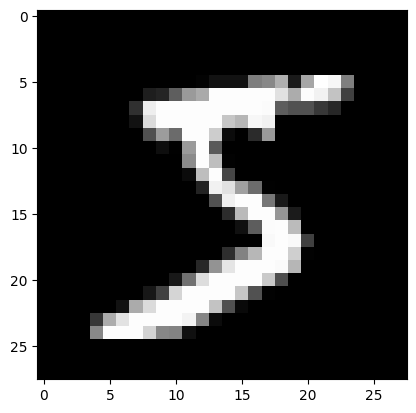

In [ ]:
image = F.to_pil_image(x_0_tensor)
plt.imshow(image, cmap='gray')

## Preparando el entrenamiento

La función [Compose](https://pytorch.org/vision/stable/generated/torchvision.transforms.v2.Compose.html#torchvision.transforms.v2.Compose) combina un secuencia de transformaciones.

In [ ]:
trans = transforms.Compose([transforms.ToTensor()])

In [ ]:
train_set.transform = trans
valid_set.transform = trans

Si nuestro conjunto de datos es un mazo de cartas, un [DataLoader](https://pytorch.org/tutorials/beginner/basics/data_tutorial.html#preparing-your-data-for-training-with-dataloaders) define cómo obtenemos las cartas del mazo para entrenar un modelo de IA.

Podríamos mostrar a nuestros modelos todo el conjunto de datos a la vez. Esto no solo requiere muchos recursos computacionales, sino que [está comprobado](https://arxiv.org/pdf/1804.07612) que usar un lote más pequeño de datos es más eficiente para el entrenamiento de modelos.

Por ejemplo, si nuestro `batch_size` es 32, entrenaremos nuestro modelo barajando el mazo y robando 32 cartas. No necesitamos mezclar para el conjunto de validación ya que el modelo no está aprendiendo, pero aún así usaremos un `batch_size` para evitar errores de memoria.

El tamaño del lote (`batch size`) es algo que decide el desarrollador del modelo y el mejor valor dependerá del problema que se resuelva. Las investigaciones muestran que 32 o 64 es suficiente para muchos problemas de aprendizaje automático y es el valor predeterminado en algunos marcos de aprendizaje automático, por lo que usaremos 32 aquí.

In [ ]:
batch_size = 32

train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(valid_set, batch_size=batch_size)

## Estructura de nuestro modelo

In [ ]:
input_size = 1 * 28 * 28

In [ ]:
n_classes = 10

layers = [
    nn.Flatten(),
    nn.Linear(input_size, 512),  # Entrada
    nn.ReLU(),  # Activación para la entrada
    nn.Linear(512, 512),  # Oculta
    nn.ReLU(),  # Activación para oculta
    nn.Linear(512, n_classes)  # Salida
]
layers

[Flatten(start_dim=1, end_dim=-1),
 Linear(in_features=784, out_features=512, bias=True),
 ReLU(),
 Linear(in_features=512, out_features=512, bias=True),
 ReLU(),
 Linear(in_features=512, out_features=10, bias=True)]

In [ ]:
nn.Sequential(
    nn.Flatten(),
    nn.Linear(input_size, 512),  # Entrada
    nn.ReLU(),  # Activación para la entrada
    nn.Linear(512, 512),  # Oculta
    nn.ReLU(),  # Activación para oculta
    nn.Linear(512, n_classes) # Salida
)

### Compilamos el modelo

In [ ]:
model = nn.Sequential(*layers)
model

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)

In [ ]:
model.to(device)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)

## Entrenamiento del modelo

#### Función de pérdida y optimización

Usaremos un tipo de función de pérdida llamada [CrossEntropy](https://pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html) que está diseñada para calificar si un modelo predijo la categoría correcta de un grupo de categorías.

In [ ]:
loss_function = nn.CrossEntropyLoss()

Recordemos que el optimizador es el algoritmo usado para poder entrenar nuestra red

In [ ]:
optimizer = Adam(model.parameters())

### Calculando la precisión

In [ ]:
train_N = len(train_loader.dataset)
valid_N = len(valid_loader.dataset)

In [ ]:
train_N

60000

A continuación, crearemos una función para calcular la precisión de cada batch. El resultado es una fracción de la precisión total, por lo que podemos sumar la precisión de cada lote para obtener el total.

In [ ]:
def get_batch_accuracy(output, y, N):
    """
    :output: Los valores de prediccion del modelo
    :y: Los valores reales de clase de las imagenes
    :N: El numero de imágenes del dataset
    """
    pred = output.argmax(dim=1, keepdim=True)
    correct = pred.eq(y.view_as(pred)).sum().item()
    return correct / N

### La función de entrenamiento

In [ ]:
def train():
    loss = 0
    accuracy = 0

    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        output = model(x)
        optimizer.zero_grad()
        batch_loss = loss_function(output, y)
        batch_loss.backward()
        optimizer.step()

        # Update de los valores de la función de pérdida y precisión
        loss += batch_loss.item()
        # Podemos cambiar la métrica objetivo
        accuracy += get_batch_accuracy(output, y, train_N)
    print('Train - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

### La función de validación

In [ ]:
def validate():
    loss = 0
    accuracy = 0

    model.eval()
    with torch.no_grad():
        for x, y in valid_loader:
            x, y = x.to(device), y.to(device)
            output = model(x)

            loss += loss_function(output, y).item()
            accuracy += get_batch_accuracy(output, y, valid_N)
    print('Valid - Loss: {:.4f} Accuracy: {:.4f}'.format(loss, accuracy))

### El ciclo de entrenamiento

In [ ]:
epochs = 5

for epoch in range(epochs):
    print('Epoch: {}'.format(epoch))
    train()
    validate()

Epoch: 0
Train - Loss: 212.2449 Accuracy: 0.9324
Valid - Loss: 31.4441 Accuracy: 0.9685
Epoch: 1
Train - Loss: 79.0900 Accuracy: 0.9742
Valid - Loss: 30.4114 Accuracy: 0.9689
Epoch: 2
Train - Loss: 52.8360 Accuracy: 0.9818
Valid - Loss: 22.2037 Accuracy: 0.9794
Epoch: 3
Train - Loss: 38.6887 Accuracy: 0.9861
Valid - Loss: 30.4153 Accuracy: 0.9709
Epoch: 4
Train - Loss: 30.0069 Accuracy: 0.9892
Valid - Loss: 21.9177 Accuracy: 0.9795


## Predicción

In [ ]:
prediction = model(x_0_tensor)
prediction

tensor([[ -8.0458,  -1.5760,   1.5541,   8.1991,  -4.9957,  -9.4211,  -9.2973,
           0.1511,  -2.0657, -10.7547]], grad_fn=<AddmmBackward0>)

In [ ]:
prediction.argmax(dim=1, keepdim=True)

tensor([[3]])

In [ ]:
y_0

3

In [ ]:
F.to_pil_image(x_0_tensor)

# Limpiando la memoria

In [ ]:
import IPython
app = IPython.Application.instance()
app.kernel.do_shutdown(True)

{'status': 'ok', 'restart': True}

# Backlog de códigos

In [ ]:
class CNNnet(torch.nn.Module):
    def __init__(self):
        super(CNNnet,self).__init__()
        self.conv1 = torch.nn.Sequential(
            # 2-D convolution
            torch.nn.Conv2d(in_channels=1, # input channels
                            out_channels=16, # convolution channels
                            kernel_size=3, # kernel size of the convolution
                            stride=2, # stride of the kernel
                            padding=1), # padding with 0
            # Data is normalized before entering ReLU，num_features=batch_size*num_features*height*width
            # Output is with size (N,C,W,H), i.e., (batch_size, channels, width, height)
            torch.nn.BatchNorm2d(16), # the input dimensionality of BatchNorm2d should match the number of convolution channels
            # Set activation function
            torch.nn.ReLU()
        )
        self.conv2 = torch.nn.Sequential(
            torch.nn.Conv2d(16,32,3,2,1), # be sure to have the number of input channels match the output channels of the previous layer
            torch.nn.BatchNorm2d(32),
            torch.nn.ReLU()
        )
        self.conv3 = torch.nn.Sequential(
            torch.nn.Conv2d(32,32,3,2,1),
            torch.nn.BatchNorm2d(32),
            torch.nn.ReLU()
        )
        self.conv4 = torch.nn.Sequential(
            torch.nn.Conv2d(32,64,2,2,0),
            torch.nn.BatchNorm2d(64),
            torch.nn.ReLU()
        )
        # set fully connected layer
        self.mlp1 = torch.nn.Linear(2*2*64,100) # input dimension should match the output dimension from the previous layer
        # final output is of dimension 10 since
        # MNIST is a 10-class classification dataset
        self.mlp2 = torch.nn.Linear(100,10)

    # feedforward
    def forward(self,x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        # flatten tensor to 1-D
        x = self.mlp1(x.view(x.size(0),-1))
        x = self.mlp2(x)
        return x